In [2]:
%reset -f
%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
plt.rcParams['figure.facecolor'] = 'white'

import os, glob

import numpy as np

from tqdm.auto import tqdm

from astropy.table import Table, vstack
from astropy.time import Time, TimeDelta
from astropy import units as u
from astropy.coordinates import SkyCoord, concatenate

import requests
import pandas as pd
pd.set_option('display.max_columns', None)

import io

# import pickle

# from fastparquet import ParquetFile

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

# TNS

In [4]:
import io
import requests

r = requests.post(
    'https://api.fink-portal.org/api/v1/resolver',
    json={
        'resolver': 'tns',
        'name': '',
        'nmax': 1000000
    }
)
tns = pd.read_json(io.BytesIO(r.content))
print(len(tns), 'TNS entries')

tns_tdes = tns[[_.startswith('TDE') and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_tdes = tns_tdes['d:internalname'].drop_duplicates().values
print(len(tns_tdes), 'unique TDEs')

249224 TNS entries
114 unique TDEs


In [5]:
tns_tdes = tns[[_.startswith('TDE') and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_tdes = tns_tdes['d:internalname'].drop_duplicates().values.astype(str)
print(len(tns_tdes), 'TDEs')

tns_nontdes = tns[[not _.startswith('TDE') and _ != 'nan' and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_nontdes = tns_nontdes['d:internalname'].drop_duplicates().values.astype(str)
print(len(tns_nontdes), 'non-TDEs')

114 TDEs
13417 non-TDEs


In [6]:
tns_types = tns[['d:internalname', 'd:fullname', 'd:type']]
tns_types = tns_types[[_.startswith('ZTF') for _ in tns_types['d:internalname'].values]]
tns_types.rename(columns={'d:internalname': 'objectId', 'd:fullname': 'tns_name', 'd:type': 'tns'}, inplace=True)
tns_types = tns_types.drop_duplicates('objectId')

In [7]:
def get_tns_info(oid=None, ra=None, dec=None, sr=5/3600):
    result = []
    
    if oid is not None:
        idx = (tns['d:internalname'] == oid) | (tns['d:fullname'] == oid)
    elif ra is not None and dec is not None:
        idx = SkyCoord(tns['d:ra'].values, tns['d:declination'].values, unit='deg').separation(SkyCoord(ra, dec, unit='deg')).deg < sr
    else:
        return None
    
    for i,row in tns[idx].iterrows():
        res = row['d:fullname']
        if row['d:type'] and row['d:type'] != 'nan':
            res += ' (' + row['d:type']
            if row['d:redshift'] > 0:
                res += f" z={row['d:redshift']}"
            res += ')'
            
        if res not in result:
            result.append(res)
        
    return " | ".join(result)

get_tns_info('ZTF20acxfcmr')

'AT 2020accc'

# Dataset with upper limits and bad quality data

In [8]:
# data = pd.read_parquet('/home/karpov/fink/tde/tde_objects_all_withupperlim_min5_1.parquet')
# data = pd.read_parquet('/home/karpov/fink/tde/tde_objects_all.parquet')
data = pd.read_parquet('/home/lmiguel/gitlab_projects/TDE classification/tde_classification/data/input/tde_objects_all_withupperlim_min5_1.parquet')


print(len(data), 'light curves')

603216 light curves


In [9]:
data = data.join(tns_types.set_index('objectId'), on='objectId')

In [10]:
# More robust, positional association, as often we do not have ZTF name listed there...

from stdpipe import astrometry # TODO: directly embed the function here

ids1,ids2,dist = astrometry.spherical_match(tns['d:ra'], tns['d:declination'], data['i:ra'], data['i:dec'], 5/3600)

# TODO: fix that stupid pandas warning
data['tns_name'][ids2] = tns['d:fullname'][ids1]
data['tns'][ids2] = tns['d:type'][ids1]

/tmp/ipykernel_59695/4237339328.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tns_name'][ids2] = tns['d:fullname'][ids1]
/tmp/ipykernel_59695/4237339328.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tns'][ids2] = tns['d:type'][ids1]


In [11]:
tns_tdes = list(set(tns_tdes) | set(data['objectId'][[_.startswith('TDE') for _ in data['tns'].values.astype(str)]]))
print(len(tns_tdes), 'TDEs')


120 TDEs


In [12]:
idx = data['tns'].astype(str) != 'nan'
idx &= [not _.startswith('TDE') for _ in data['tns'].values.astype(str)]
tns_nontdes = list(set(tns_nontdes) | set(data['objectId'][idx]))
print(len(tns_nontdes), 'non-TDEs')

13847 non-TDEs


In [13]:
idx = data['tns_name'].astype(str) != 'nan'
tns_all = list(set(data['objectId'][idx]))
print(len(tns_all), 'total TNS')

31363 total TNS


# Nearests, as a separate table

In [14]:
# nearests = pd.read_parquet('/home/karpov/fink/tde/nearests_all_5.parquet')
input_dir = '/home/lmiguel/gitlab_projects/TDE classification/tde_classification/data/input'
nearests = pd.read_parquet(os.path.join(input_dir, 'nearests_all_5.parquet'))

nearests.loc[nearests['distnr_g']<0, 'distnr_g'] = np.nan
nearests.loc[nearests['distnr_r']<0, 'distnr_r'] = np.nan
# nearests['distnr'] = np.nanmin([nearests['distnr_g'], nearests['distnr_r']], axis=0)



# Aux functions

In [15]:
from matplotlib.colors import LinearSegmentedColormap

COLORS_ZTF = {1: "#15284F", 2: "#F5622E", 3: "#3C8DFF", 4: "#D5D5D3"}

fink_colormap = LinearSegmentedColormap.from_list('fink-3colors', [COLORS_ZTF[1], COLORS_ZTF[3], COLORS_ZTF[2]])

from dustmaps.sfd import SFDQuery

sfd = SFDQuery()

# Coefficients for ZTF filters for G23 extinction law from dust_extinction for Rv=3.1
Av = {1: 3.681, 2: 2.635, 3: 1.944}

def deredden(flux, fid, ra, dec):
    # De-reddening using SFD from dustmaps
    Ebv = sfd(SkyCoord(ra, dec, unit='deg'))
    
    return flux / 10**(-0.4*(Ebv*Av[fid]))

def deredden_pdf(pdf, ra=None, dec=None):
    # De-reddening using SFD from dustmaps
    Ebv = sfd(SkyCoord(ra, dec, unit='deg'))
    for fid in [1,2,3]:
        idx = pdf['i:fid'] == fid
        pdf.loc[idx, 'FLUXCAL'] /= 10**(-0.4*(Ebv*Av[fid]))
        pdf.loc[idx, 'FLUXCALERR'] /= 10**(-0.4*(Ebv*Av[fid]))
        
        if 'FLUXCALUPPER' in pdf:
            pdf.loc[idx, 'FLUXCALUPPER'] /= 10**(-0.4*(Ebv*Av[fid]))
    
def get_lc(row):
    # Extract light curve from the data row
    pdf = pd.DataFrame({_: row[_] for _ in ['i:fid', 'i:jd', 'i:magpsf', 'i:sigmapsf', 'i:isdiffpos', 'FLUXCAL', 'FLUXCALERR']})
    
    if 'i:diffmaglim' in row:
        pdf['i:diffmaglim'] = row['i:diffmaglim']
        pdf['FLUXCALUPPER'] = 10**(11 - 0.4*pdf['i:diffmaglim'])
    
    pdf['i:mjd'] = pdf['i:jd'] - 2400000.5
    pdf.sort_values('i:jd', inplace=True, ignore_index=True)
    
    # Remove other bands?..
    pdf = pdf[(pdf['i:fid'] == 1) | (pdf['i:fid'] == 2)]
    
    deredden_pdf(pdf, row['i:ra'], row['i:dec'])
    
    return pdf

def plot_lc(pdf, show_zero=False, show_limits=False, ms=None, err_alpha=0.2, err_lw=None):
    for fid,cn,c in [(1, 'g', COLORS_ZTF[1]), (2, 'r', COLORS_ZTF[2])]:
        idx = pdf['i:fid'] == fid
        mjd = pdf['i:jd'] - 2400000.5
        
        plt.errorbar(mjd[idx], pdf['FLUXCAL'][idx], pdf['FLUXCALERR'][idx], fmt='.', c=c, alpha=err_alpha, lw=err_lw)
        plt.plot(mjd[idx], pdf['FLUXCAL'][idx], '.', color=c, alpha=1, ms=ms, label=cn)

        if show_limits and 'FLUXCALUPPER' in pdf:
            idx &= ~np.isfinite(pdf['FLUXCAL'])
            plt.plot(mjd[idx], pdf['FLUXCALUPPER'][idx], '^', alpha=0.3, color=c)

    plt.grid(alpha=0.2)
    if show_zero:
        plt.axhline(0, ls='--', color='black', alpha=0.2)


In [16]:
def get_slope(x, y, dy):
    x = np.atleast_1d(x)
    y = np.atleast_1d(y)
    dy = np.atleast_1d(dy)
    
    idx = np.isfinite(x) & np.isfinite(y) & np.isfinite(dy)
    
    if len(x[idx]) < 3 or np.ptp(x[idx]) == 0:
        return 0,0
    
    p,cov = np.polyfit(
        x[idx] - np.mean(x[idx]), 
        y[idx] - np.mean(y), 
        1, w=1/dy[idx], cov='unscaled'
    )
    dp = np.sqrt(np.diag(cov))
    
    return p[0], dp[0]

def is_rising(jd, flux, fluxerr, fid, upper=None, nsigmas_rise=2, nsigmas_decay=1, nsigmas_slope=3, use_slope=True, verbose=False):
    idx0 = flux == flux

    is_decay = False
    is_rise = False
    
    for fid1 in [1, 2]:
        idx = idx0 & (fid == fid1)
        uidx = ~idx0 & (fid == fid1)
        if np.sum(idx) < 2:
            continue

        # Last point is significantly lower than the max?..
        diff = flux[idx][:-1] - flux[idx][-1]
        differr = np.hypot(fluxerr[idx][:-1], fluxerr[idx][-1])

        if np.any(diff > nsigmas_decay*differr):
            is_decay = True

        # Last point is significantly higher than the min?..
        diff = flux[idx][-1] - flux[idx][:-1]

        if np.any(diff > nsigmas_rise*differr):
            is_rise = True
            
        if np.sum(idx) >= 3 and use_slope:
            # Slope is significantly positive?..
            slope,serr = get_slope(jd[idx], flux[idx], fluxerr[idx])
            if verbose:
                print('slope', slope, '+/-', serr)
            if slope > nsigmas_slope*serr:
                is_rise = True
            
        # Any point is significantly lower than the previous?..
        diff = flux[idx][:-1] - flux[idx][1:]
        differr = np.hypot(fluxerr[idx][:-1], fluxerr[idx][1:])

        if np.any(diff > nsigmas_decay*differr):
            is_decay = True
            
        # Last point is significantly higher than any (prior) upper limit?..
        if upper is not None and np.sum(uidx) > 0:
            diff = flux[idx][-1] - upper[uidx]
            differr = fluxerr[idx][-1]
            
            if np.any(diff > nsigmas_rise*differr):
                is_rise = True
                            
    if verbose:
        print('rise', is_rise, 'decay', is_decay)
            
    return is_rise and not is_decay

In [17]:
def cleanup_limits(sub, ignore=False):
    if ignore:
        sub = sub[np.isfinite(sub['FLUXCAL'])]  

    elif 'FLUXCALUPPER' in sub:
        mask = np.isfinite(sub['i:jd']) 

        for fid in [1,2]:
            idx1 = sub['i:fid'] == fid # Same filter
            idx2 = np.isfinite(sub['FLUXCAL']) # Detections
            
            # jd1 = np.min(sub['i:jd'][idx1 & idx2]) # First detection, same filter
            jd1 = np.min(sub['i:jd'][idx2]) # First detection, any filter
            flux1 = (sub['FLUXCAL'][sub['i:jd']==jd1]).values[0]
            idx3 = sub['i:jd'] >= jd1 - 1 # Later than first detection
            # idx3 |= sub['FLUXCALUPPER'] > flux1 # ..or above first detection?..
            idx3 |= sub['FLUXCALUPPER'] > np.nanmin(sub['FLUXCAL'][idx1]) # ..or above min flux?..

            mask[idx1 & ~idx2 & idx3] = False
            
        sub = sub[mask]
        
    else:
        # Dataset without upper limits defined
        sub = sub.assign(FLUXCALUPPER = np.nan)

    return sub

# Feature extraction

In [483]:
from light_curve.light_curve_py import RainbowFit

# Filters ZTF
filt_conv = {1: "g", 2: "r", 3: "i"}  # Conversion between filter ID (int) and filter name (str)
band_wave_aa = {"g": 4770.0, "r": 6231.0, "i": 7625.0}  # Bands in angstroms for rainbow

feature = RainbowFit.from_angstrom(
    band_wave_aa, 
    with_baseline = False,
    temperature='constant',
    bolometric='sigmoid'
)

def extract_features(sub):
    jd = sub['i:jd'].values
    flux,fluxerr = sub['FLUXCAL'].values, sub['FLUXCALERR'].values
    flux_upper = sub['FLUXCALUPPER'].values
    fluxerr_upper = sub['FLUXCALUPPER'].values/5

    idx_good = (flux == flux)
    
    band=np.array([filt_conv[_] for _ in sub['i:fid']])

    try:
        params,errors,cov = feature._eval_and_get_errors(
            t=jd, 
            m=np.where(idx_good, flux, flux_upper), 
            sigma=np.where(idx_good, fluxerr, fluxerr_upper), 
            band=band, 
            upper_mask=~idx_good, 
            return_covariance=True,
            debug=True, 
        )

        result = {}
        result['params'] = params
        result['errors'] = errors
        result['cov'] = cov
        
        return result
    except KeyboardInterrupt:
        raise
    except:
        return None

def print_features(res1):
    for i,name in enumerate(feature.names):
        value,error = res1['params'][i], res1['errors'][i]
        
        if name in ['rise_time', 'T', 'amplitude']:
            snr = f" (S/N = {value/error:.1f})"
        else:
            snr = ''
            
        if name == 'reference_time':
            value -= 2400000.5
            
        print(f"{name} = {value:.1f} +/- {error:.1f}{snr}")
    print(f"r_chisq = {res1['params'][-1]:.1f}")

def plot_features(sub, res1, nsamples=100, prior=100, jd_min=None, jd_max=None, extra=None, **kwargs):
    if jd_min is not None:
        sub = sub[sub['i:jd'] >= jd_min]
    if jd_max is not None:
        sub = sub[sub['i:jd'] <= jd_max]
        
    plot_lc(sub, **kwargs)

    if prior:
        t = np.linspace(np.max(sub['i:jd']) - prior, np.max(sub['i:jd']) + 1, 1000)
    else:
        t = np.linspace(np.min(sub['i:jd']) - 1, np.max(sub['i:jd']) + 1, 1000)

    for iter in range(nsamples):
        params1 = np.random.multivariate_normal(res1['params'][:-1], res1['cov'])
        if params1[feature.p['amplitude']] < 0:
            continue
        for fid,c,col in ((0, 'g', COLORS_ZTF[1]), (1, 'r', COLORS_ZTF[2])):
            plt.plot(
                t - 2400000.5, 
                feature.model(t, c, *params1), 
                color=col, alpha=0.03
            )

    for c,col in [('g', COLORS_ZTF[1]), ('r', COLORS_ZTF[2])]:
        plt.plot(
            t - 2400000.5,
            feature.model(t, [c], *res1['params']),
            '--', color=col, alpha=0.5
        )

    texts = []
    for i,name in enumerate(feature.names):
        value,error = res1['params'][i], res1['errors'][i]
        
        if name in ['rise_time', 'T', 'amplitude']:
            snr = f" (S/N = {value/error:.1f})"
        else:
            snr = ''
            
        if name == 'reference_time':
            value -= 2400000.5
            
        texts.append(f"{name} = {value:.1f} +/- {error:.1f}{snr}")
    texts.append(f"r_chisq = {res1['params'][-1]:.1f}")

    if extra is not None:
        texts += extra # TODO: check whether it is a list
        
    plt.text(
        0.05, 0.95, 
        "\n".join(texts), 
        transform=plt.gca().transAxes, 
        va='top', 
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.7}
    )

/home/karpov/.local/lib/python3.13/site-packages/light_curve/light_curve_py/warnings.py:19: ExperimentalWarning: Function light_curve.light_curve_py.features.rainbow.generic.RainbowFit is experimental and may cause any kind of troubles
  warn_experimental(message)


# Pre-extracted features

In [19]:
from early_tde_classification.config import Config

# Load pre-computed features
# features = Table.read('features.all.pmulti.distnr.ext.vot')
features = Table.read(os.path.join(Config.OUT_FEATURES_DIR, 'features_sergey_2025', 'features.all.pmulti.distnr.vot'))

features.rename_column('T', 'temperature')
features.rename_column('e_T', 'e_temperature')
features.rename_column('snr_T', 'snr_temperature')

# # Restore dicts in 'raw' column
# array = np.array
# for row in tqdm(features):
#     row['raw'] = eval(row['raw'])


In [20]:
# Load the classifier 
import xgboost as xgb
clf = xgb.XGBClassifier()
clf.load_model('early_tde_xgboost.final.dereddened.ubj')
clf_nodistnr = xgb.XGBClassifier()
clf_nodistnr.load_model('early_tde_xgboost.final.dereddened.nodistnr.ubj')

tde_score = clf.predict(features[list(clf.feature_names_in_)].to_pandas())
tde_score_nodistnr = clf_nodistnr.predict(features[list(clf_nodistnr.feature_names_in_)].to_pandas())


In [21]:
maybe_tdes = ['ZTF24aamfius', 'ZTF25aagfhmz', 'ZTF25aaknwwy', 'ZTF25aagrecw', 'ZTF20abjwvae']
additional_tdes = ['ZTF18aabtxvd', 'ZTF18actaqdw', 'ZTF18acnbpmd', 'ZTF19aakiwze', 'ZTF19abhejal', 'ZTF19abhhjcc', 'ZTF20aamqmfk', 'ZTF18aakelin', 'ZTF20abjwvae', 'ZTF20abefeab', 'ZTF20abowque', 'ZTF20abrnwfc', 'ZTF20abnorit']
ant_tdes = ['ZTF22aadesap', 'ZTF21abxowzx', 'ZTF20acvfraq', 'ZTF20abgxlut']

In [22]:
good_idx = features['r_chisq'] < 10

good_idx &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window

# good_idx &= features['num_prehist_detections'] <= 1 # No more than 1 detection prior to the window
good_idx &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window

good_idx &= features['e_reference_time'] < 100

good_idx &= features['norm_rel_reference_time'] < 0
good_idx &= features['norm_rel_reference_time'] > -10

# good_idx &= features['snr_amplitude'] > 1.5
good_idx &= features['snr_rise_time'] > 1.5
good_idx &= features['snr_temperature'] > 1.5

good_idx &= features['pcounter'] == 0 # Only last sets of features for every peak

# good_idx &= features['distnr'] < 1.5

# tns_idx = np.isin(features['objectId'], tns_tdes + tns_nontdes) # Everything in TNS

tns_all_idx = np.isin(features['objectId'], tns_all) # all in TNS
tde_idx = np.isin(features['objectId'], tns_tdes + maybe_tdes + additional_tdes) # TDEs in TNS
sn_idx = np.array([_.startswith('SN') for _ in features['tns']]) # SNe in TNS
sn_idx |= np.array([_.startswith('SLSN') for _ in features['tns']]) # SNe in TNS

print(np.sum(good_idx), 'good')
print(np.sum(good_idx & tns_all_idx), 'good TNS')
print(np.sum(good_idx & tde_idx), 'good TDEs')
print(np.sum(good_idx & sn_idx), 'good SNe')

12600 good
8867 good TNS
42 good TDEs
3956 good SNe


In [23]:
len(features)

349104

In [24]:
np.sum(~labels)

NameError: name 'labels' is not defined

# Plotting of candidates

In [489]:
plt.rcParams['font.size'] = 12

In [545]:
def mag2fluxcal(magpsf, sigmapsf, isdiffpos=None):
    if magpsf is None:
        return None, None

    fluxcal = 10 ** (-0.4 * magpsf) * 10 ** (11)
    fluxcal_err = 9.21034 * 10**10 * np.exp(-0.921034 * magpsf) * sigmapsf

    if isdiffpos is not None:
        sign = np.where(isdiffpos == 'f', -1, 1)
    else:
        sign = 1
        
    return sign*fluxcal, fluxcal_err

def request_lc_snad(ra, dec, sr_arcsec=1.5):
    r = requests.get(
        "https://db.ztf.snad.space/api/v3/data/latest/circle/full/json",
        params={'ra': ra, 'dec': dec, 'radius_arcsec': sr_arcsec},
    )

    lc = []
    for k,v in r.json().items():
        lc1 = pd.DataFrame(v['lc'])
        lc1['filter'] = v['meta']['filter']
        lc1['i:fid'] = {'zg': 1, 'zr': 2, 'zi': 3}.get(v['meta']['filter'])
        lc.append(lc1)
        
    if len(lc):
        pdf = pd.concat(lc, ignore_index=True)

        pdf['i:jd'] = pdf['mjd'] + 2400000.5
        pdf['FLUXCAL'],pdf['FLUXCALERR'] = mag2fluxcal(pdf['mag'], pdf['magerr'])
        deredden_pdf(pdf, ra, dec)
    else:
        pdf = None
        
    return pdf

In [26]:
already_found = [
'ZTF18aasvknh',
'ZTF20aazyvre',
'ZTF21aazenvp',
'ZTF21abvydim',
'ZTF22aaizrty',
'ZTF23aajsmul',
'ZTF23abihmun',
'ZTF23abowyjf',
'ZTF23abprgop',
'ZTF24aaimfrw',
'ZTF24abwywkf',
'ZTF23aajnfna',
'ZTF21abvpudz',
'ZTF20abaeuwr',
'ZTF20abluzvg',
'ZTF21aagokfi',
'ZTF21acdpfwu',
'ZTF22aarvrcz',
'ZTF22aayyrvn',
'ZTF23abjvojy',
'ZTF20aavqrzc',
'ZTF20abfybfo',
'ZTF20abjwqqq',
'ZTF20abjwqqq',
'ZTF20ablxoya',
'ZTF20acvezvs',
'ZTF20acxtaau',
'ZTF21aapxqdr',
'ZTF21abtwrzu',
'ZTF22aajnyhg',
'ZTF22aajnyhg',
'ZTF22absuavp',
'ZTF23aabuqia',
'ZTF24aafvgzk',
'ZTF20aatpzog',
'ZTF20aaznovd',
'ZTF20abfrbru',
'ZTF22aalpehr',
]

len(np.unique(already_found))

36

1559 candidates
29 candidates that are already found
0 ZTF17aabahdu True 1 1


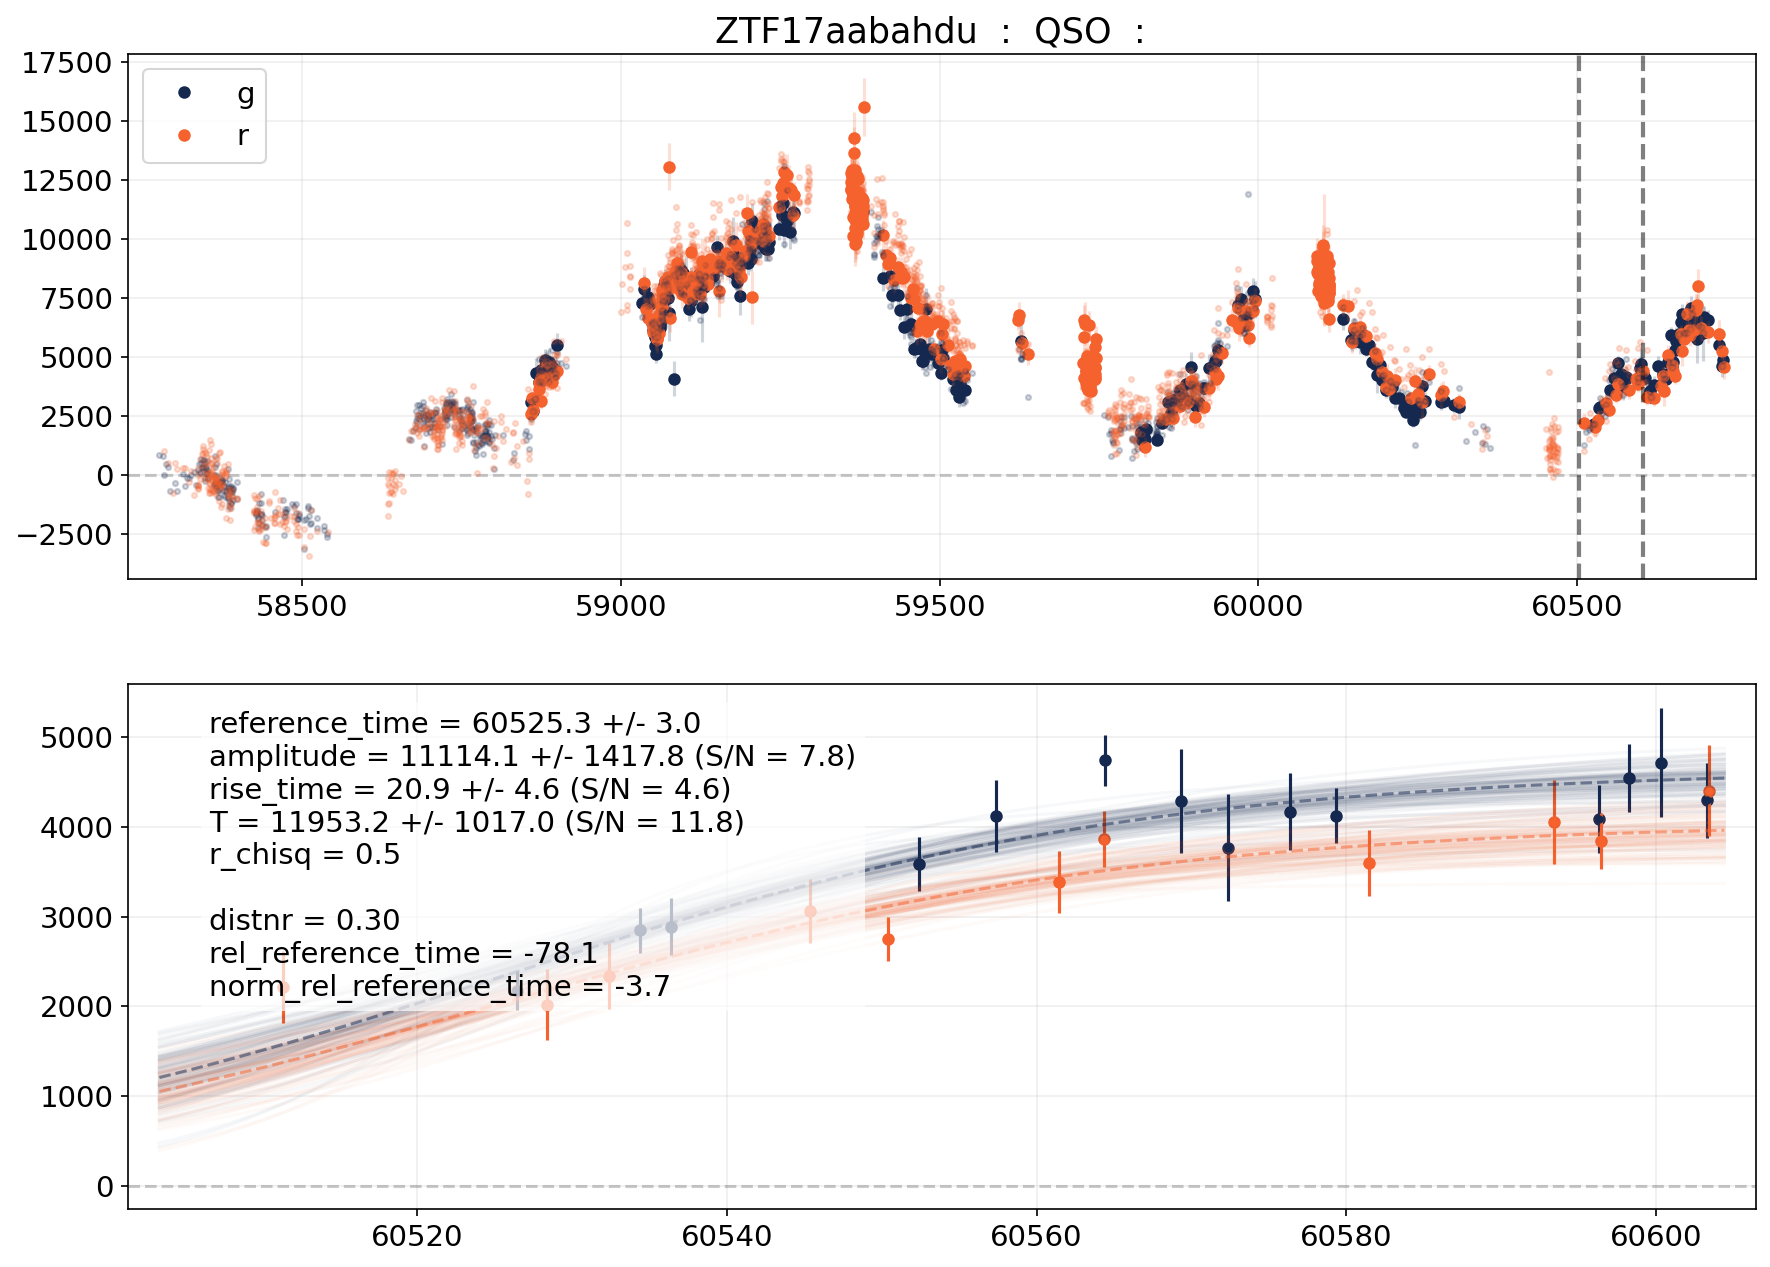

In [546]:
cand_idx = (tde_score == 1) | (tde_score_nodistnr == 1)
# cand_idx &= good_idx & ~tns_all_idx & (tde_score == 1) # Good non-TNS candidates
# cand_idx &= good_idx & tns_all_idx # Good TNS candidates
cand_idx &= good_idx # Good candidates
# cand_idx &= good_idx & ~tns_all_idx # Good non-TNS candidates
cand_idx &= ~tde_idx # Exclude known TDEs
cand_idx &= ~sn_idx # Exclude known SNe
# cand_idx &= tde_idx # only known TDEs
# cand_idx &= features['num_prehist_negatives'] > 1

cand_idx &= features['tns'] == 'nan'

# cand_idx = np.isin(features['objectId'], already_found)
# cand_idx &= features['distnr'] > 0.4
# cand_idx = np.isin(features['objectId'], ['ZTF22absuavp'])
# cand_idx = features['objectId'] == 'ZTF18aankgjw'
# cand_idx &= features['counter']-features['pcounter']==38
# cand_idx &= features['rise_time'] > 10
# cand_idx &= features['num_prehist_detections'] <= 1 # Exclude everything with history prior to 100 days
# cand_idx &= features['num_prehist_detections'] <= 1
# cand_idx &= features['num_prehist_negatives'] <= 1
cand_idx &= features['pcounter'] == 0
# cand_idx &= features['distnr'] > 1


cand_found_idx = cand_idx & np.isin(features['objectId'], already_found)
# cand_idx &= ~np.isin(features['objectId'], already_found)

print(np.sum(cand_idx), 'candidates')
print(np.sum(cand_found_idx), 'candidates that are already found')

for i,cand in enumerate(features[cand_idx]):
#     if i < 500:
#         continue
    print(i, cand['objectId'], good_idx[cand_idx][i], tde_score[cand_idx][i], tde_score_nodistnr[cand_idx][i])
#     display(cand)
    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    sub = full[(full['i:jd'] >= cand['jd_min']) & (full['i:jd'] <= cand['jd_max'])]
    sub = cleanup_limits(sub)
        
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    snad = request_lc_snad(ra, dec, 1.5)
    
    plt.figure(figsize=(14,10))
    plt.subplot(2, 1, 1)
    plot_lc(full, show_limits=False, show_zero=True, ms=10)
    
    # SNAD
    if snad is not None:
        for c,cn,fid in ((COLORS_ZTF[1], 'g', 1), (COLORS_ZTF[2], 'r', 2)):
            idx = nearests['objectId'] == cand['objectId']
            idx &= (np.isfinite(nearests['magnr_'+cn])) & (nearests['distnr_'+cn] < 1.5)
            if np.sum(idx):
                flux0 = 10**(11 - 0.4*np.mean(nearests['magnr_'+cn][idx]))
                flux0 = deredden(flux0, fid, ra, dec)
            else:
                flux0 = 0

            idx = snad['i:fid'] == fid
            plt.plot(snad['i:jd'][idx]-2400000.5, snad['FLUXCAL'][idx] - flux0, '.', ms=5, alpha=0.2, color=c)
            
    plt.axvline(cand['jd_min']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    
#     plt.axvspan(cand['jd_min']-2400000.5-100, cand['jd_min']-2400000.5, color='gray', hatch='//', fc='white', lw=0.5, alpha=0.5)
    plt.title(cand['objectId'] + '  :  ' + cand['type'] + '  :  ' + get_tns_info(ra=ra, dec=dec))
    plt.margins(0.02, 0.05)

    plt.legend(loc='upper left')
    
    plt.subplot(2, 1, 2)
    plot_features(
        sub, cand['raw'], show_limits=True, show_zero=True, prior=100, 
        ms=10, err_alpha=1,
        extra=[
            '', 
            f"distnr = {cand['distnr']:.2f}", 
            f"rel_reference_time = {cand['rel_reference_time']:.1f}",
            f"norm_rel_reference_time = {cand['norm_rel_reference_time']:.1f}",
        ]
    )
    
#     plt.title(f"best fit score = {tde_score[cand_idx][i]} {tde_score_nodistnr[cand_idx][i]}")
    plt.margins(0.02, 0.05)
    
#     plt.xlabel('Modified Julian Date')
    
    plt.show()
    
#     if i > 500:
#         break
    
    break

In [541]:
snad

,mjd,mag,magerr,clrcoeff,filter,i:fid,i:jd,FLUXCAL,FLUXCALERR
0,58275.46820,16.602000,0.016823,-0.102664,zg,1,2.458276e+06,22866.516029,354.298095
1,58280.44696,16.603497,0.016829,-0.086177,zg,1,2.458281e+06,22835.009678,353.940516
2,58283.44633,16.637120,0.016972,-0.065702,zg,1,2.458284e+06,22138.694127,346.073320
3,58286.44896,16.618540,0.016892,-0.092491,zg,1,2.458287e+06,22520.809657,350.381472
4,58289.42638,16.622200,0.016908,-0.054247,zg,1,2.458290e+06,22445.020169,349.525154
...,...,...,...,...,...,...,...,...,...
2561,60463.46336,16.190662,0.011890,0.095790,zr,2,2.460464e+06,33399.133522,365.762109
2562,60463.46769,16.144144,0.011735,0.105830,zr,2,2.460464e+06,34861.205425,376.791489
2563,60466.45998,16.192356,0.011896,0.103672,zr,2,2.460467e+06,33347.063767,365.370297
2564,60466.46394,16.196093,0.011909,0.097630,zr,2,2.460467e+06,33232.483669,364.508236


In [542]:
deredden_pdf(snad, ra, dec)
snad

24.422054346858197 33.15974645619393 0.04363385
    1 1.1594352
    2 1.1117064
    3 1.0812589


,mjd,mag,magerr,clrcoeff,filter,i:fid,i:jd,FLUXCAL,FLUXCALERR
0,58275.46820,16.602000,0.016823,-0.102664,zg,1,2.458276e+06,26512.243061,410.785674
1,58280.44696,16.603497,0.016829,-0.086177,zg,1,2.458281e+06,26475.713489,410.371085
2,58283.44633,16.637120,0.016972,-0.065702,zg,1,2.458284e+06,25668.380745,401.249581
3,58286.44896,16.618540,0.016892,-0.092491,zg,1,2.458287e+06,26111.418932,406.244603
4,58289.42638,16.622200,0.016908,-0.054247,zg,1,2.458290e+06,26023.545934,405.251758
...,...,...,...,...,...,...,...,...,...
2561,60463.46336,16.190662,0.011890,0.095790,zr,2,2.460464e+06,37130.028096,406.620052
2562,60463.46769,16.144144,0.011735,0.105830,zr,2,2.460464e+06,38755.422684,418.881483
2563,60466.45998,16.192356,0.011896,0.103672,zr,2,2.460467e+06,37072.141821,406.184471
2564,60466.46394,16.196093,0.011909,0.097630,zr,2,2.460467e+06,36944.762400,405.226113


In [527]:
ra, dec

(24.422054346858197, 33.15974645619393)

In [517]:
np.unique(features[cand_idx]['tns'])

nan


In [206]:
'ZTF18aanlzzf' in features['objectId'][good_idx]

True

In [500]:
plt.rcParams['font.size'] = 14

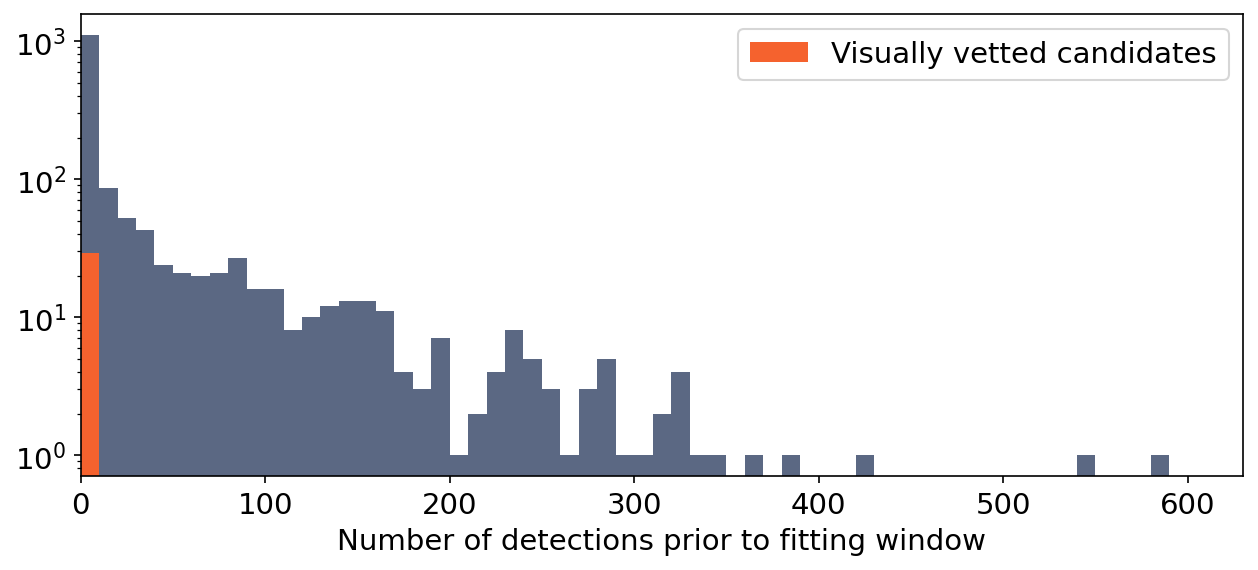

In [549]:
plt.figure(figsize=(10,4))

plt.hist(features['num_prehist_detections'][cand_idx | cand_found_idx], range=(0, 600), bins=60, label=None, alpha=0.7, color=COLORS_ZTF[1])
plt.hist(features['num_prehist_detections'][cand_found_idx], range=(0, 600), bins=60, label='Visually vetted candidates', color=COLORS_ZTF[2])
plt.yscale('log')
plt.xlim(0,)
plt.legend()
plt.xlabel('Number of detections prior to fitting window')
plt.savefig('/home/karpov/fink/tde/figures/fig_num_prehist_detections.pdf', bbox_inches='tight')


# Plotting for the paper

In [67]:
import matplotlib.patheffects as fx

plt.rcParams['font.size'] = 14

ZTF18adcbgey True 1 1


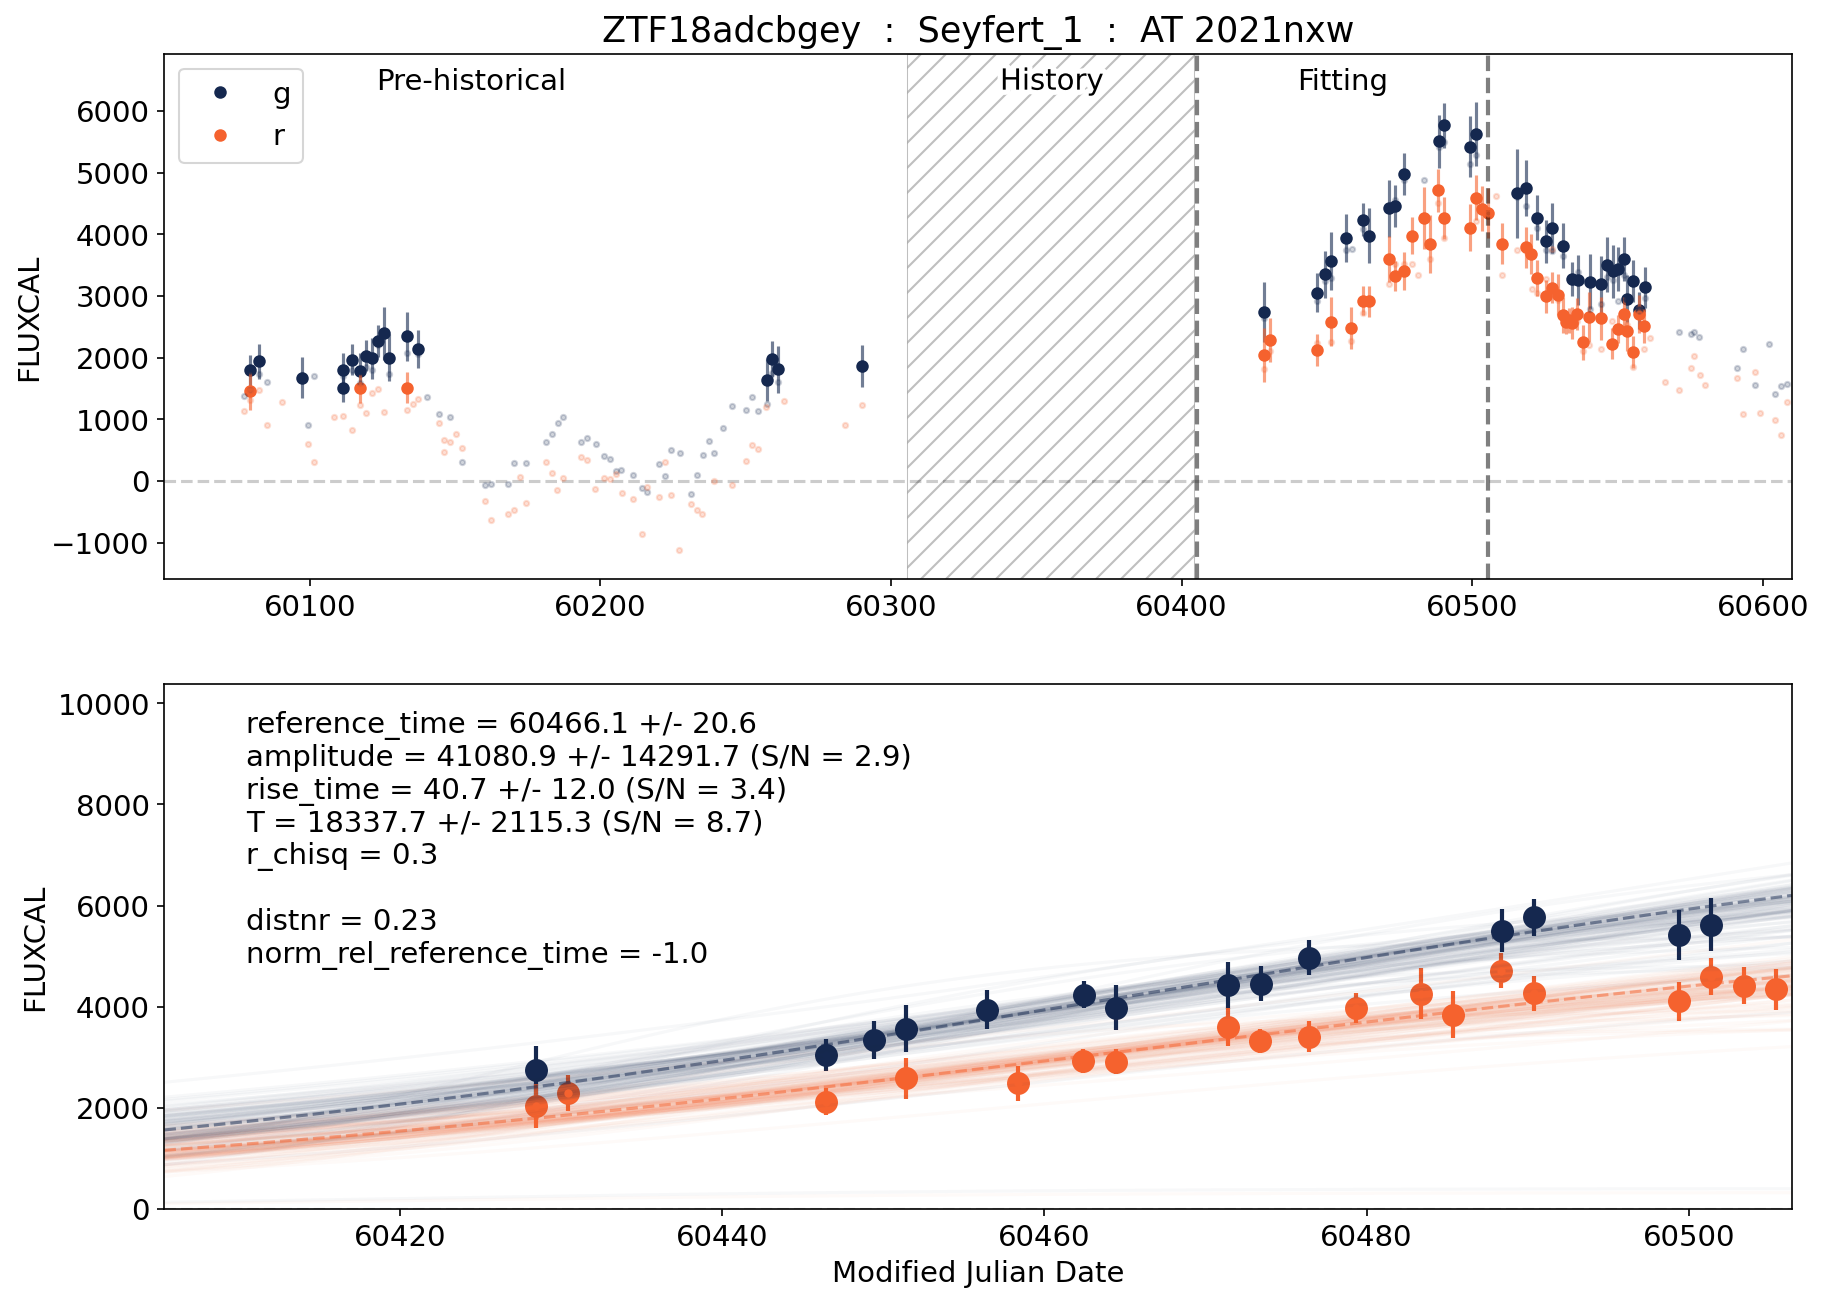

In [550]:
cand_idx = features['objectId'] == 'ZTF18adcbgey'
cand_idx &= features['jd_max'] == 2460505.8950347

for i,cand in enumerate(features[cand_idx]):
    print(cand['objectId'], good_idx[cand_idx][i], tde_score[cand_idx][i], tde_score_nodistnr[cand_idx][i])

    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    sub = full[(full['i:jd'] >= cand['jd_min']) & (full['i:jd'] <= cand['jd_max'])]
    sub = cleanup_limits(sub)
        
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    snad = request_lc_snad(ra, dec, 1.5)
    
    plt.figure(figsize=(14,10))
    plt.subplot(2, 1, 1)
    plot_lc(full, show_limits=False, show_zero=True, ms=10, err_alpha=0.6)
    plt.grid(None)
    
    # SNAD
    if snad is not None:
        for c,cn,fid in ((COLORS_ZTF[1], 'g', 1), (COLORS_ZTF[2], 'r', 2)):
            idx = nearests['objectId'] == cand['objectId']
            idx &= (np.isfinite(nearests['magnr_'+cn])) & (nearests['distnr_'+cn] < 1.5)
            if np.sum(idx):
                flux0 = 10**(11 - 0.4*np.mean(nearests['magnr_'+cn][idx]))
                flux0 = deredden(flux0, fid, ra, dec)
            else:
                flux0 = 0

            idx = snad['i:fid'] == fid
            plt.plot(snad['i:jd'][idx]-2400000.5, snad['FLUXCAL'][idx] - flux0, '.', ms=5, alpha=0.2, color=c)
            
    plt.axvline(cand['jd_min']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    
    plt.axvspan(cand['jd_min']-2400000.5-100, cand['jd_min']-2400000.5-1, color='gray', hatch='//', fc='white', lw=0.5, alpha=0.5)
    plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5, 1.1*np.max(full['FLUXCAL']), 'Fitting', ha='center')
    plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5-100, 1.1*np.max(full['FLUXCAL']), 'History', ha='center').set_path_effects([fx.Stroke(linewidth=5, foreground='white'), fx.Normal()])
    plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5-300, 1.1*np.max(full['FLUXCAL']), 'Pre-historical', ha='center')

    plt.title(cand['objectId'] + '  :  ' + cand['type'] + '  :  ' + get_tns_info(ra=ra, dec=dec))
    plt.margins(0.02, 0.05)
#     plt.xlim(59600, )
    plt.xlim(60050, 60610)

    plt.ylim(None, 1.2*np.max(full['FLUXCAL']))
    plt.ylabel('FLUXCAL')
    
    plt.legend(loc='upper left')
    
    plt.subplot(2, 1, 2)
    plot_features(
        sub, cand['raw'], show_limits=True, show_zero=True, prior=100,
        ms=20, err_alpha=1, err_lw=2,
        extra=[
            '', 
            f"distnr = {cand['distnr']:.2f}", 
#             f"rel_reference_time = {cand['rel_reference_time']:.1f}",
            f"norm_rel_reference_time = {cand['norm_rel_reference_time']:.1f}",
        ]
    )
    
#     plt.title(f"best fit score = {tde_score[cand_idx][i]} {tde_score_nodistnr[cand_idx][i]}")
    plt.margins(0.0, 0.05)
    plt.ylim(0, 1.8*np.max(full['FLUXCAL']))
    plt.grid(None)

    
    plt.xlabel('Modified Julian Date')
    plt.ylabel('FLUXCAL')

    plt.savefig('/home/karpov/fink/tde/figures/fig_rainbow_example.pdf', bbox_inches='tight')
    plt.show()
    


ZTF18adcbgey True 1 1


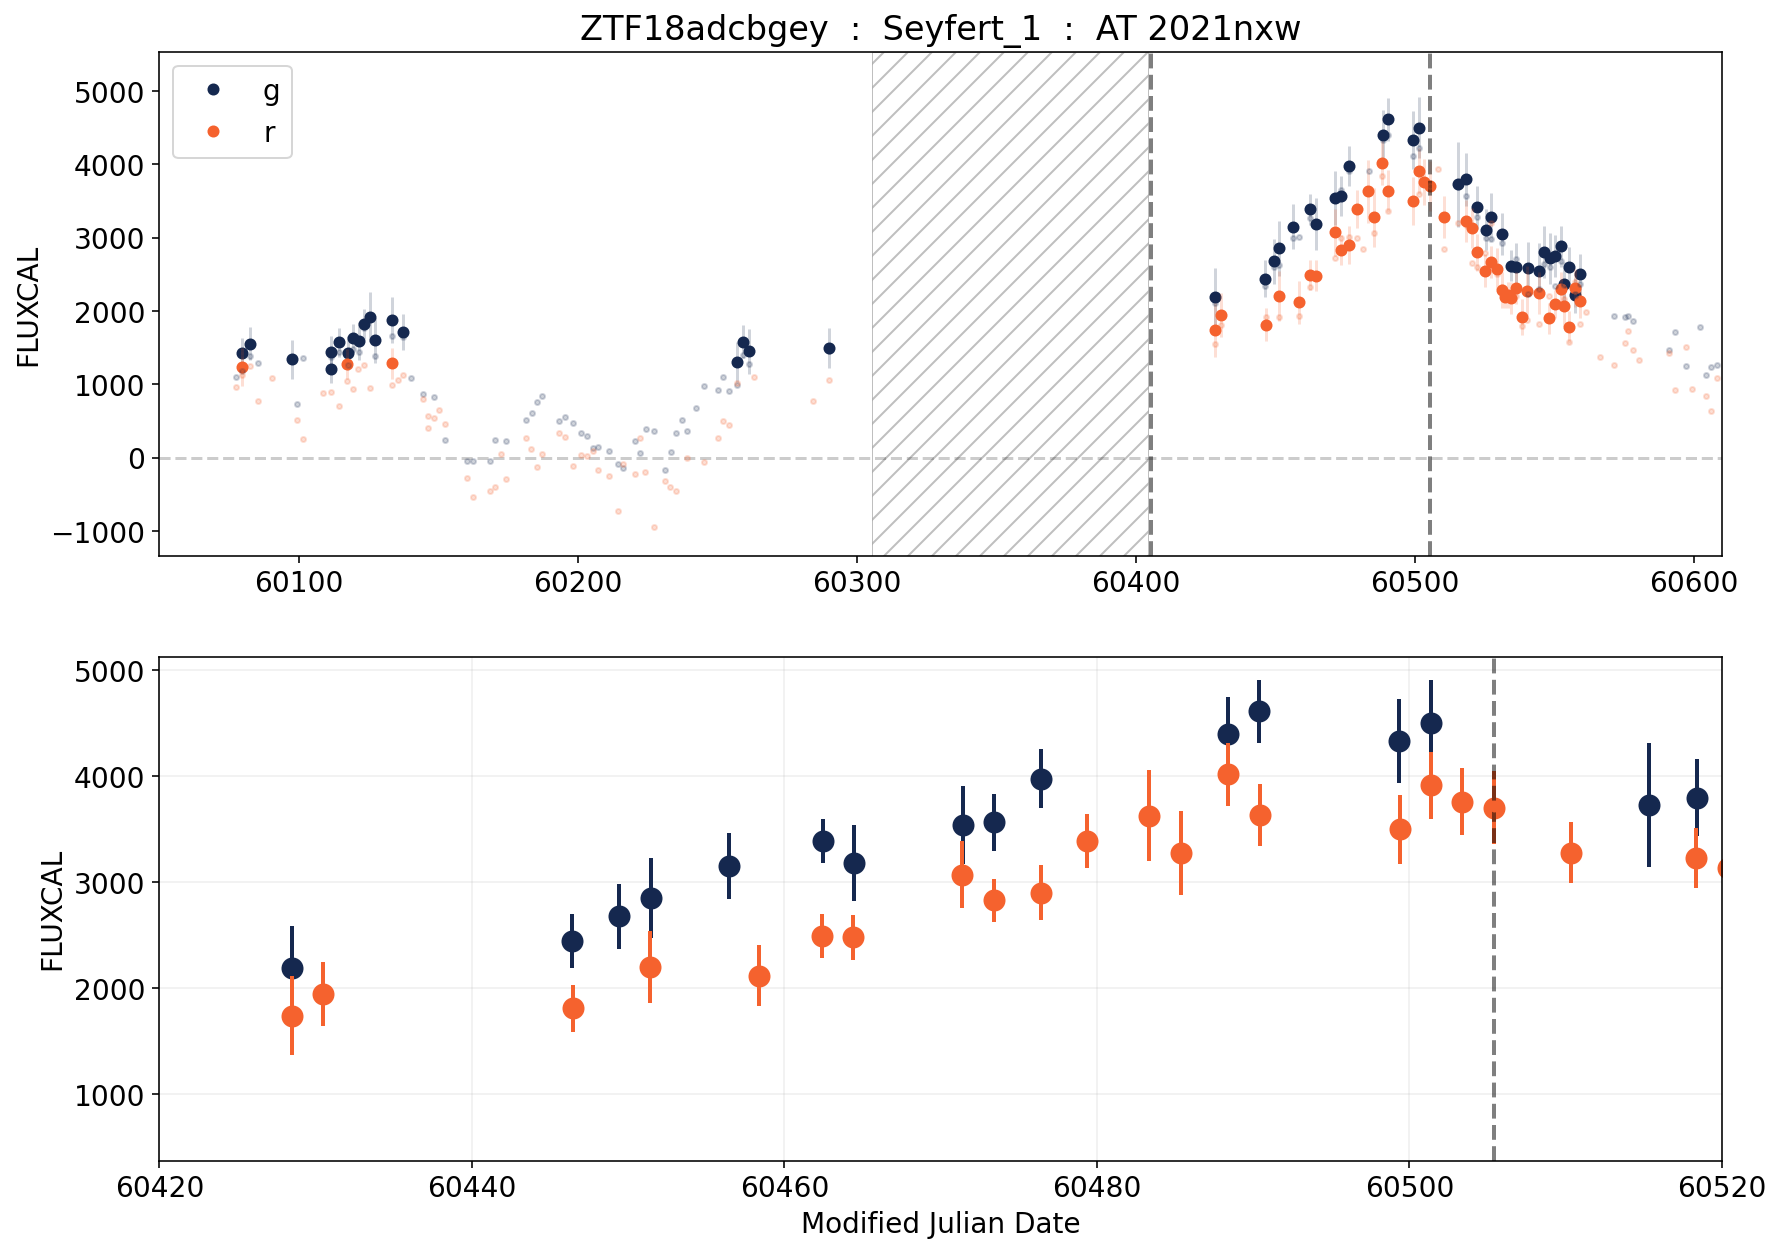

In [190]:
cand_idx = features['objectId'] == 'ZTF18adcbgey'
cand_idx &= features['jd_max'] == 2460505.8950347

for i,cand in enumerate(features[cand_idx]):
    print(cand['objectId'], good_idx[cand_idx][i], tde_score[cand_idx][i], tde_score_nodistnr[cand_idx][i])

    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    sub = full[(full['i:jd'] >= cand['jd_min']) & (full['i:jd'] <= cand['jd_max'])]
    sub = cleanup_limits(sub)
        
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    snad = request_lc_snad(ra, dec, 1.5)
    
    plt.figure(figsize=(14,10))
    plt.subplot(2, 1, 1)
    plot_lc(full, show_limits=False, show_zero=True, ms=10)
    plt.grid(None)
    
    # SNAD
    if snad is not None:
        for c,cn,fid in ((COLORS_ZTF[1], 'g', 1), (COLORS_ZTF[2], 'r', 2)):
            idx = nearests['objectId'] == cand['objectId']
            idx &= (np.isfinite(nearests['magnr_'+cn])) & (nearests['distnr_'+cn] < 1.5)
            if np.sum(idx):
                flux0 = 10**(11 - 0.4*np.mean(nearests['magnr_'+cn][idx]))
            else:
                flux0 = 0

            idx = snad['i:fid'] == fid
            plt.plot(snad['i:jd'][idx]-2400000.5, snad['FLUXCAL'][idx] - flux0, '.', ms=5, alpha=0.2, color=c)
            
    plt.axvline(cand['jd_min']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    
    plt.axvspan(cand['jd_min']-2400000.5-100, cand['jd_min']-2400000.5-1, color='gray', hatch='//', fc='white', lw=0.5, alpha=0.5)
#     plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5, 1.1*np.max(full['FLUXCAL']), 'Rising', ha='center')
#     plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5-100, 1.1*np.max(full['FLUXCAL']), 'History', ha='center').set_path_effects([fx.Stroke(linewidth=5, foreground='white'), fx.Normal()])
#     plt.text(0.5*(cand['jd_min']+cand['jd_max'])-2400000.5-300, 1.1*np.max(full['FLUXCAL']), 'Pre-historical', ha='center')

    plt.title(cand['objectId'] + '  :  ' + cand['type'] + '  :  ' + get_tns_info(ra=ra, dec=dec))
    plt.margins(0.02, 0.05)
    plt.xlim(60050, 60610)

    plt.ylim(None, 1.2*np.max(full['FLUXCAL']))
    plt.ylabel('FLUXCAL')
    
    plt.legend(loc='upper left')
    
    plt.subplot(2, 1, 2)
    
    plot_lc(full, ms=20, err_alpha=1, err_lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.xlim(60420, 60520)
    plt.margins(0.05, 0.05)
    
#     plt.ylim(0, 1.8*np.max(full['FLUXCAL']))
    plt.grid(alpha=0.2)

    
    plt.xlabel('Modified Julian Date')
    plt.ylabel('FLUXCAL')

#     plt.savefig('/home/karpov/fink/tde/figures/fig_rainbow_example.pdf', bbox_inches='tight')
    plt.show()
    


## First score time 

In [552]:
oids = np.unique(features[tde_idx & ((tde_score==1) | (tde_score_nodistnr==1))]['objectId'])
oids0 = np.unique(features[good_idx & ~tde_idx & ((tde_score==1) | (tde_score_nodistnr==1))]['objectId'])

diff = features['counter']-features['pcounter']
    
val1,val2,val3 = [],[],[]

for oid in tqdm(list(set(oids) | set(oids0))):
# for oid in tqdm(list(set(oids))):
    idx0 = features['objectId'] == oid

    idx0 &= (tde_score==1) | (tde_score_nodistnr==1)
    idx0 &= features['r_chisq'] < 10

    idx0 &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window

    idx0 &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window

    idx0 &= features['e_reference_time'] < 100

    idx0 &= features['norm_rel_reference_time'] < 1
    idx0 &= features['norm_rel_reference_time'] > -10

    idx0 &= features['snr_rise_time'] > 1.5
    idx0 &= features['snr_temperature'] > 1.5

    for diff1 in np.unique(diff[idx0]):
        idx = idx0 & (diff == diff1)
    
        lc = get_lc(data[data['objectId']==oid].iloc[0])

        aidx = np.argsort(features['jd_max'][idx])[0]

        rise_time = features['rise_time'][idx][aidx]
        jd_max = features['jd_max'][idx][aidx]
        jd_max_last = np.max(features['jd_max'][idx])

        lc = lc[np.isfinite(lc['FLUXCAL'])]
        lc = lc[lc['i:jd'] > jd_max - 100]
        lc = lc[lc['i:jd'] <= jd_max]
        jd_first = np.min(lc['i:jd'])

#         if jd_max_last - jd_first > 100:
#             raise
            
        if jd_max - jd_first < 0:
            raise

        val1.append(jd_max - jd_first)
        val2.append(jd_max_last - jd_first)
        if oid in oids:
            val3.append(1)
        else:
            val3.append(0)    
                
val1,val2,val3 = [np.array(_) for _ in (val1,val2,val3)]

  0%|          | 0/1831 [00:00<?, ?it/s]

KeyboardInterrupt: 

Text(0.5, 0, 'Peak time since first detection, days')

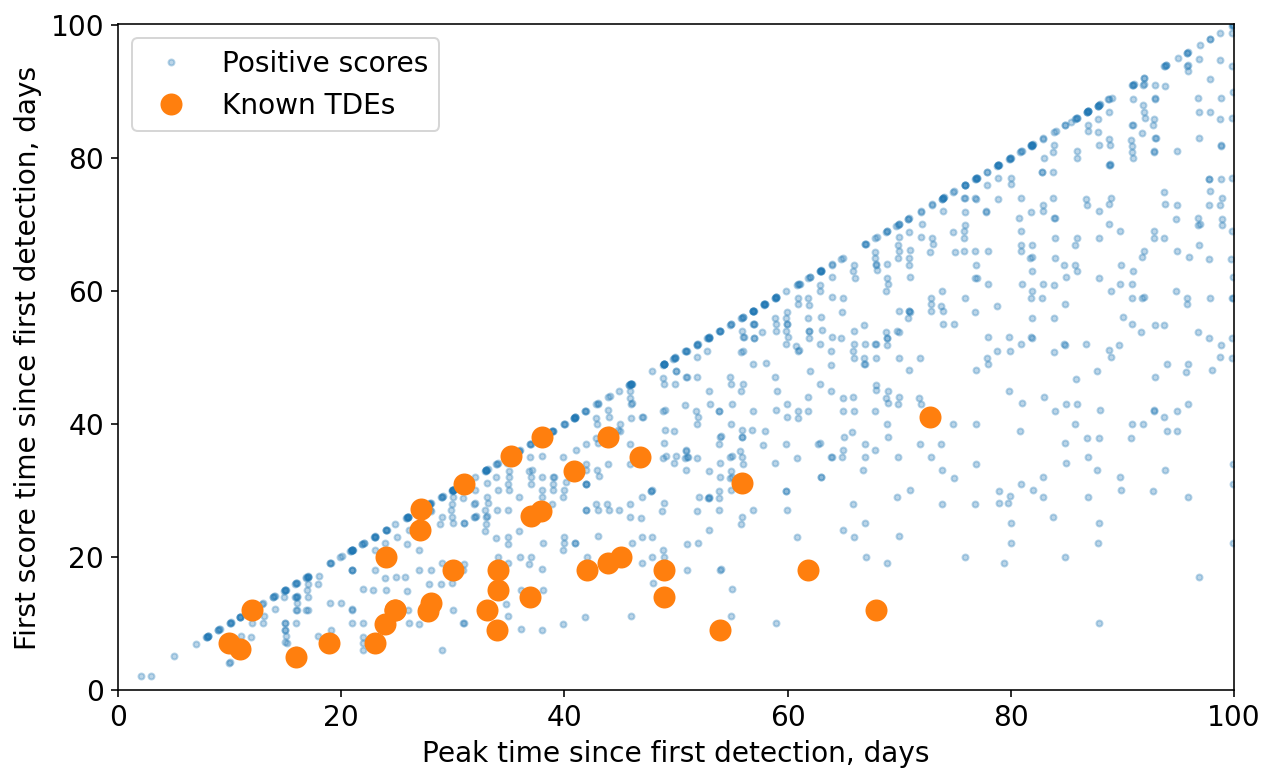

In [73]:
plt.figure(figsize=(10,6))

idx = val3 == 0
plt.plot(val2[idx], val1[idx], '.', color='C0', alpha=0.3, label='Positive scores')
idx = val3 == 1
plt.plot(val2[idx], val1[idx], 'o', ms=10, color='C1', label='Known TDEs')
    
plt.legend()
# plt.plot([4, 75], [4, 75], '--', color='gray')

plt.xlim(0, 100)
plt.ylim(0, 100.03)

plt.ylabel('First score time since first detection, days')
plt.xlabel('Peak time since first detection, days')

# plt.savefig('/home/karpov/fink/tde/figures/fig_first_score.pdf', bbox_inches='tight')


# First score tile, LOO way


In [27]:
colnames = list(clf.feature_names_in_)
colnames_nodistnr = list(clf_nodistnr.feature_names_in_)

idx = good_idx & tns_all_idx # Train on all labelled TNS objects
idx &= features['pcounter'] == 0 # Only train on latest pre-peak alerts
oids = features['objectId'][idx]
X = features[colnames][idx].to_pandas()
X_nodistnr = features[colnames_nodistnr][idx].to_pandas()
labels = (tde_idx[idx] == True) #& (features['rise_time'][idx] > 2)

pos_weight = np.sum(~labels)/np.sum(labels)

print(len(X), "rows for classification")
print(np.sum(labels), "TDEs")

diff = features['counter']-features['pcounter']

val0,val1,val2,val3,val4 = [],[],[],[],[]

# for oid in tqdm(list(oids[labels]) + already_found):
for oid in tqdm(list(oids[labels])):
    idx = oids != oid
    
    # With distnr
    clf1 = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, max_depth=3, subsample=0.2, learning_rate=0.02, reg_lambda=5, reg_alpha=10, min_child_weight=10, colsample_bytree=0.7, random_state=1)

    # Without distnr
    clf1_nodistnr = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, max_depth=3, subsample=0.1, learning_rate=0.02, reg_lambda=5, reg_alpha=10, min_child_weight=10, colsample_bytree=1.0, random_state=1)

    clf1.fit(X[idx], labels[idx]) # Train on the whole dataset
    clf1_nodistnr.fit(X_nodistnr[idx], labels[idx]) # Train on the whole dataset

    
    idx0 = features['objectId'] == oid
    idx0 &= (clf1.predict(features[colnames].to_pandas()) == 1) | (clf1_nodistnr.predict(features[colnames_nodistnr].to_pandas()) == 1)
    idx0 &= features['r_chisq'] < 10

    idx0 &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window

    idx0 &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window

    idx0 &= features['e_reference_time'] < 100

    idx0 &= features['norm_rel_reference_time'] < 0
    idx0 &= features['norm_rel_reference_time'] > -10

    idx0 &= features['snr_rise_time'] > 1.5
    idx0 &= features['snr_temperature'] > 1.5

    for diff1 in np.unique(diff[idx0]):
        idx = idx0 & (diff == diff1)
    
        lc = get_lc(data[data['objectId']==oid].iloc[0])

        aidx = np.argsort(features['jd_max'][idx])[0]

        rise_time = features['rise_time'][idx][aidx]
        jd_max = features['jd_max'][idx][aidx]
        jd_max_last = np.max(features['jd_max'][idx])

        lc = lc[np.isfinite(lc['FLUXCAL'])]
        lc = lc[lc['i:jd'] > jd_max - 100]
        lc = lc[lc['i:jd'] <= jd_max]
        jd_first = np.min(lc['i:jd'])

#         if jd_max_last - jd_first > 100:
#             raise
            
        if jd_max - jd_first < 0:
            raise

        val0.append(oid)
        val1.append(jd_max - jd_first)
        val2.append(jd_max_last - jd_first)
        val3.append(1 if oid in already_found else 0)
        val4.append(len(lc))
                        
val1,val2,val3,val4 = [np.array(_) for _ in (val1,val2,val3,val4)]

8867 rows for classification
42 TDEs


  0%|          | 0/42 [00:00<?, ?it/s]

100%|██████████| 42/42 [00:21<00:00,  1.93it/s]


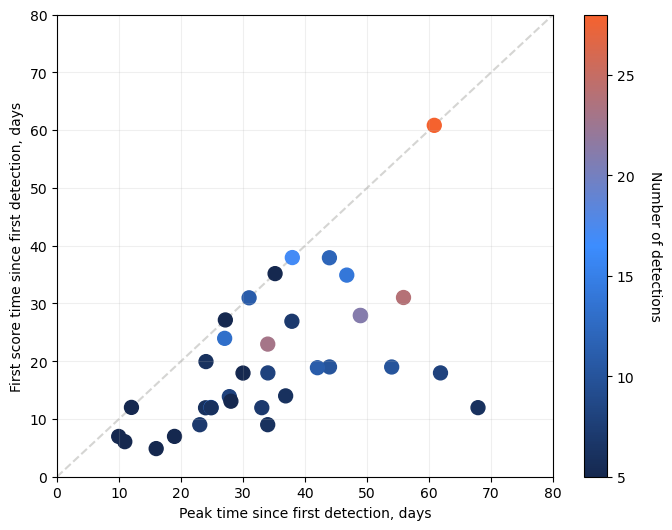

In [29]:
plt.figure(figsize=(8,6))

# idx = val3 == 1
# plt.plot(val2[idx], val1[idx], 'o', color=COLORS_ZTF[1], alpha=1, label='Candidates')
idx = val3 == 0
# plt.plot(val2[idx], val1[idx], 'o', ms=10, color=COLORS_ZTF[2], label='Known TDEs')
plt.scatter(val2[idx], val1[idx], marker='o', s=100, c=val4[idx], cmap=fink_colormap)
plt.colorbar(format='%d').set_label('Number of detections', rotation=270, labelpad=20)

# plt.legend()
# plt.plot([4, 75], [4, 75], '--', color='gray')

plt.xlim(0, 80)
plt.ylim(0, 80)

plt.ylabel('First score time since first detection, days')
plt.xlabel('Peak time since first detection, days')

plt.plot([0, 80], [0, 80], '--', color=COLORS_ZTF[4], zorder=0)
plt.grid(alpha=0.2)

# plt.savefig('/home/karpov/fink/tde/figures/fig_first_score_loo.pdf', bbox_inches='tight')


Text(0.5, 1.0, 'Cumulative fraction of the rise for first identification')

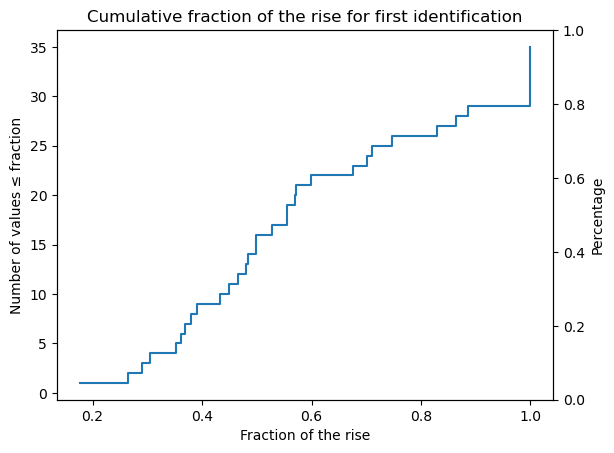

In [ ]:
val1, val2

fraction = val1/val2

# Sort values
sorted_frac = np.sort(fraction)

# Counts for ECDF
counts = np.arange(1, len(sorted_frac) + 1)

fig, ax1 = plt.subplots()

# Plot counts
ax1.step(sorted_frac, counts, where="post")
ax1.set_xlabel("Fraction of the rise")
ax1.set_ylabel("Number of values ≤ fraction")

# Add secondary y-axis for proportions
ax2 = ax1.twinx()
# ax2.step(sorted_frac, counts / len(sorted_frac), where="post", color="r", linestyle="--")
ax2.set_ylabel("Percentage")


plt.title("Cumulative fraction of the rise for first identification")


In [70]:
print(len(fraction[fraction<=0.25])/len(fraction))
print(len(fraction[fraction<=1/3])/len(fraction))
print(len(fraction[fraction<=0.4])/len(fraction))

print(len(fraction[fraction<=0.5])/len(fraction))
print(len(fraction[fraction<=2/3])/len(fraction))
print(len(fraction[fraction<=0.75])/len(fraction))

0.02857142857142857
0.11428571428571428
0.2571428571428571
0.45714285714285713
0.6285714285714286
0.7428571428571429


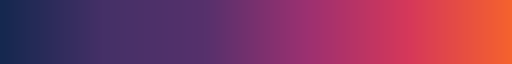

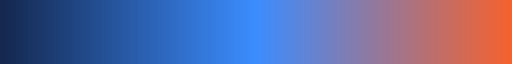

In [116]:
from matplotlib.colors import LinearSegmentedColormap

display(LinearSegmentedColormap.from_list('fink-6colors', ['#15284f', '#453067', '#56316c', '#9c3071', '#d6385a', '#f5622e']))
display(LinearSegmentedColormap.from_list('fink-3colors', [COLORS_ZTF[1], COLORS_ZTF[3], COLORS_ZTF[2]]))

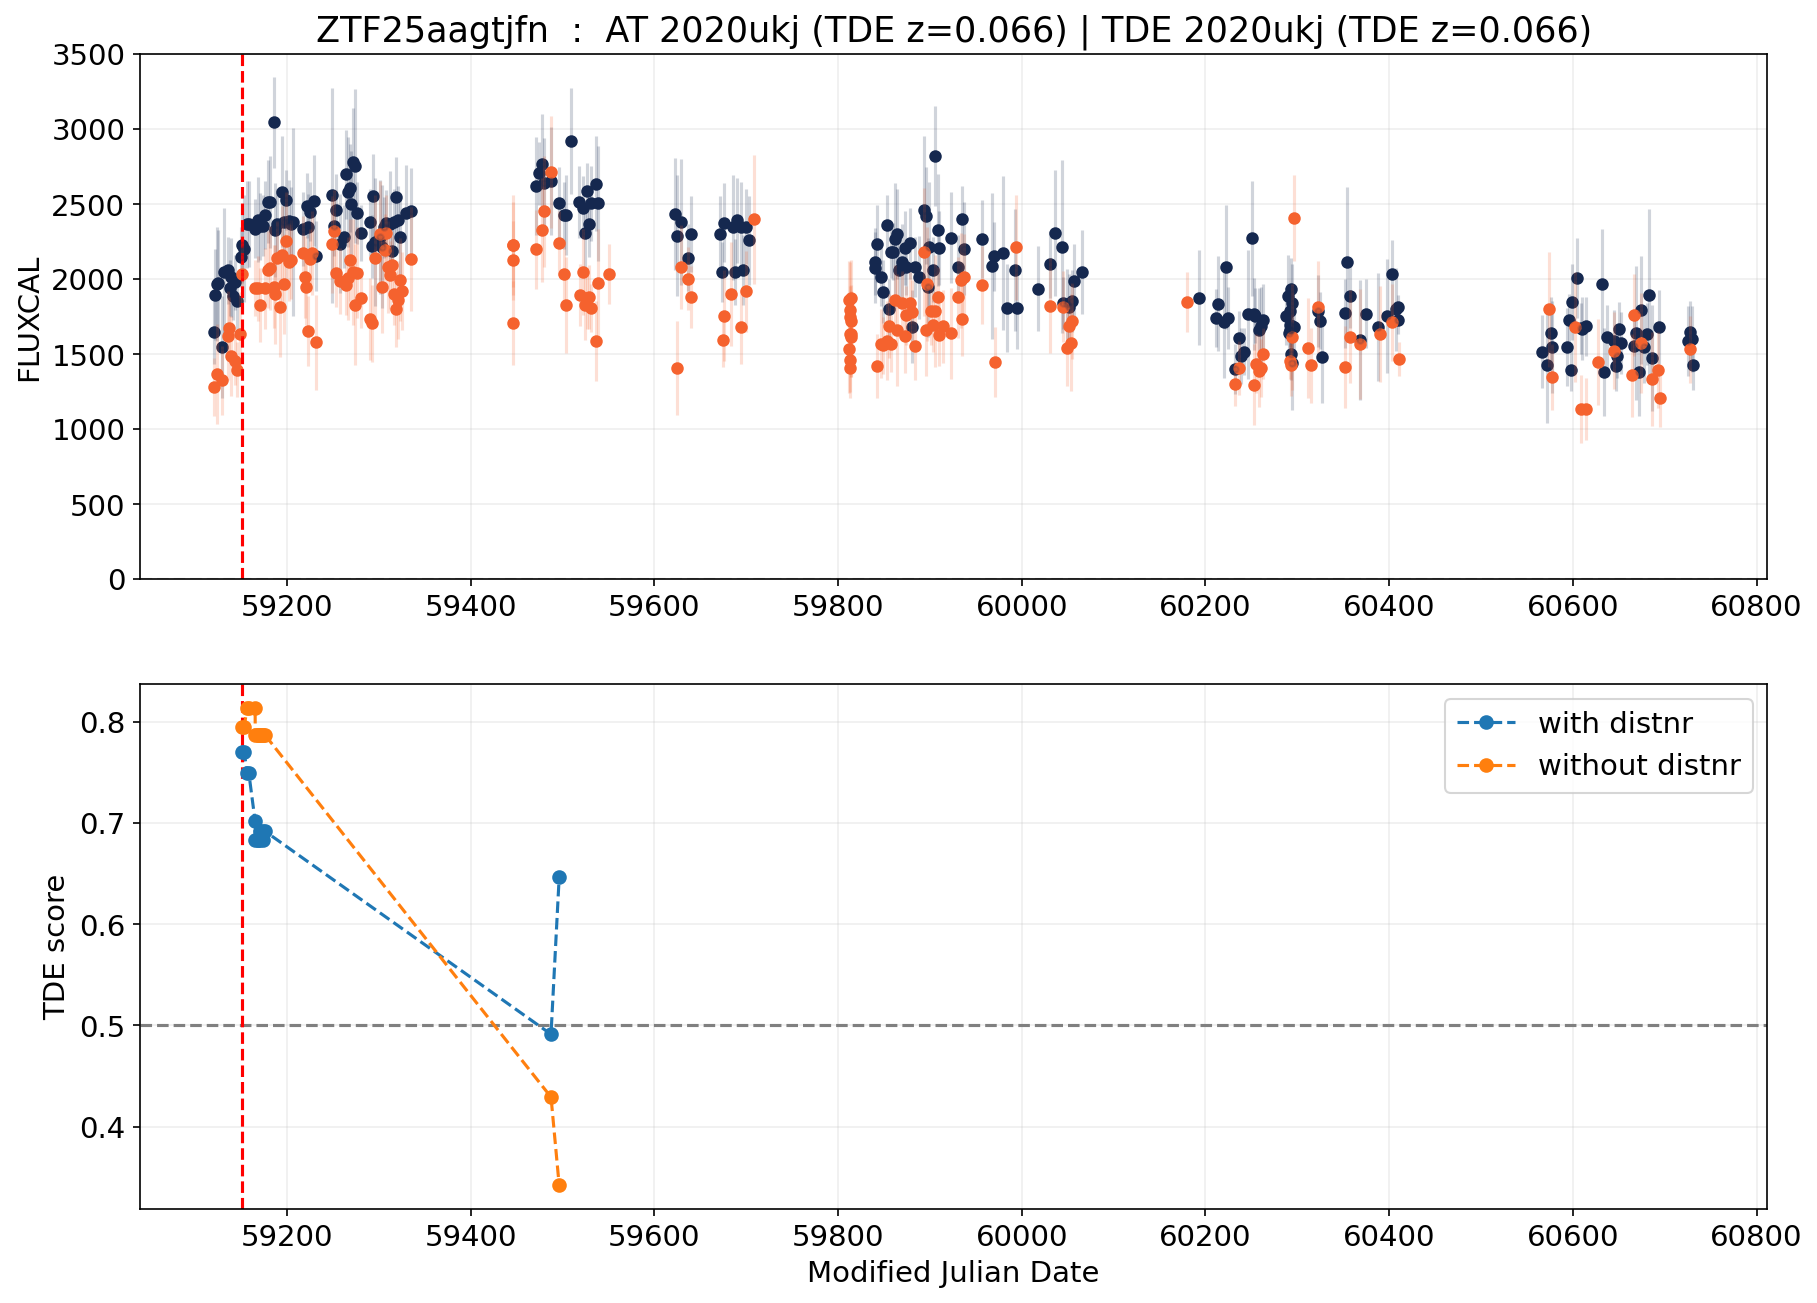

In [450]:
ra,dec = np.mean(data[data['objectId']==oid][['i:ra', 'i:dec']], axis=0)

lc = get_lc(data[data['objectId']==oid].iloc[0])

plt.figure(figsize=(14, 10))
ax = plt.subplot(2,1,1)
plot_lc(lc, show_limits=False, show_zero=True, ms=10)
plt.grid(None)
# plt.xlim(None, 59200)
plt.grid(alpha=0.2)

tns_info = get_tns_info(ra=ra, dec=dec) or 'no TNS info'
plt.title(cand['objectId'] + '  :  ' + tns_info)
plt.ylabel('FLUXCAL')

plt.axvline(jd_max-2400000.5, ls='--', color='red')
plt.ylim(0, 3500)

ax2 = plt.subplot(2,1,2, sharex=ax)
plt.xlabel('Modified Julian Date')
plt.ylabel('TDE score')
plt.grid(alpha=0.2)
plt.axhline(0.5, color='gray', ls='--')

plt.axvline(jd_max-2400000.5, ls='--', color='red')

idx = features['objectId']==oid
# idx &= idx0
aidx = np.argsort(features['jd_max'][idx])

proba1 = clf1.predict_proba(features[colnames][idx][aidx].to_pandas())[:, 1]
proba2 = clf1_nodistnr.predict_proba(features[colnames_nodistnr][idx][aidx].to_pandas())[:, 1]

plt.plot(features['jd_max'][idx][aidx]-2400000.5, proba1, 'o--', label='with distnr')
plt.plot(features['jd_max'][idx][aidx]-2400000.5, proba2, 'o--', label='without distnr')
plt.legend()

In [448]:
val2,val1,val4

(array([15.9912731, 27.148507 , 43.9466551, 41.9999768, 18.9482176,
        42.9782176, 33.9807523, 33.0283912, 43.9341783, 55.8833565]),
 array([ 4.8716666, 27.148507 , 19.0115047, 18.8782523,  6.9820833,
        11.9600231,  9.0100926, 11.9565046, 37.9158449, 31.0339004]),
 array([ 5,  5, 10, 11,  5,  6,  6,  7, 12, 24]))

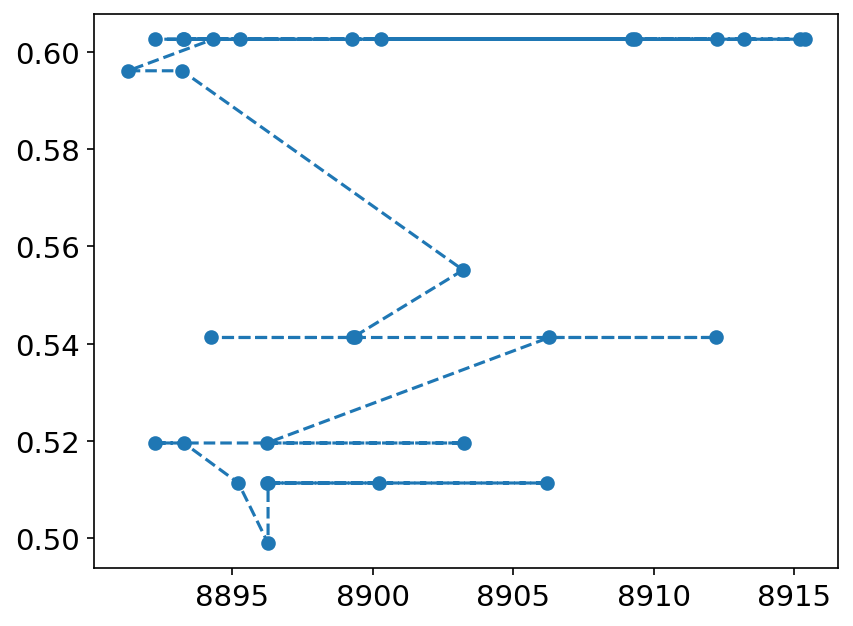

In [436]:
plt.plot(features['jd_max'][idx]-2450000.5, proba1, 'o--')


# Example objects

In [ ]:
import matplotlib.patheffects as fx

plt.rcParams['font.size'] = 14

In [313]:
example_objs = [
    'ZTF23abjvojy', # QSO, two very strong variability episodes almost fifteen years apart. Repeated Ambiguous Nuclear Transient?..
    'ZTF22abzajwl', # AT2023adr - repeating TDE
    'ZTF20accxwrk', # AT2020ukj - long-duration brightening of a until-then passive galaxy. Could be a TDE, but the timescales are very long.
    'ZTF19aayijkh', # AT2022yhf - long-duration brightening of a blue, slightly variable object that is likely an AGN. No cooling down in the decay. Hints of infrared echo.
]

ZTF22absuavp


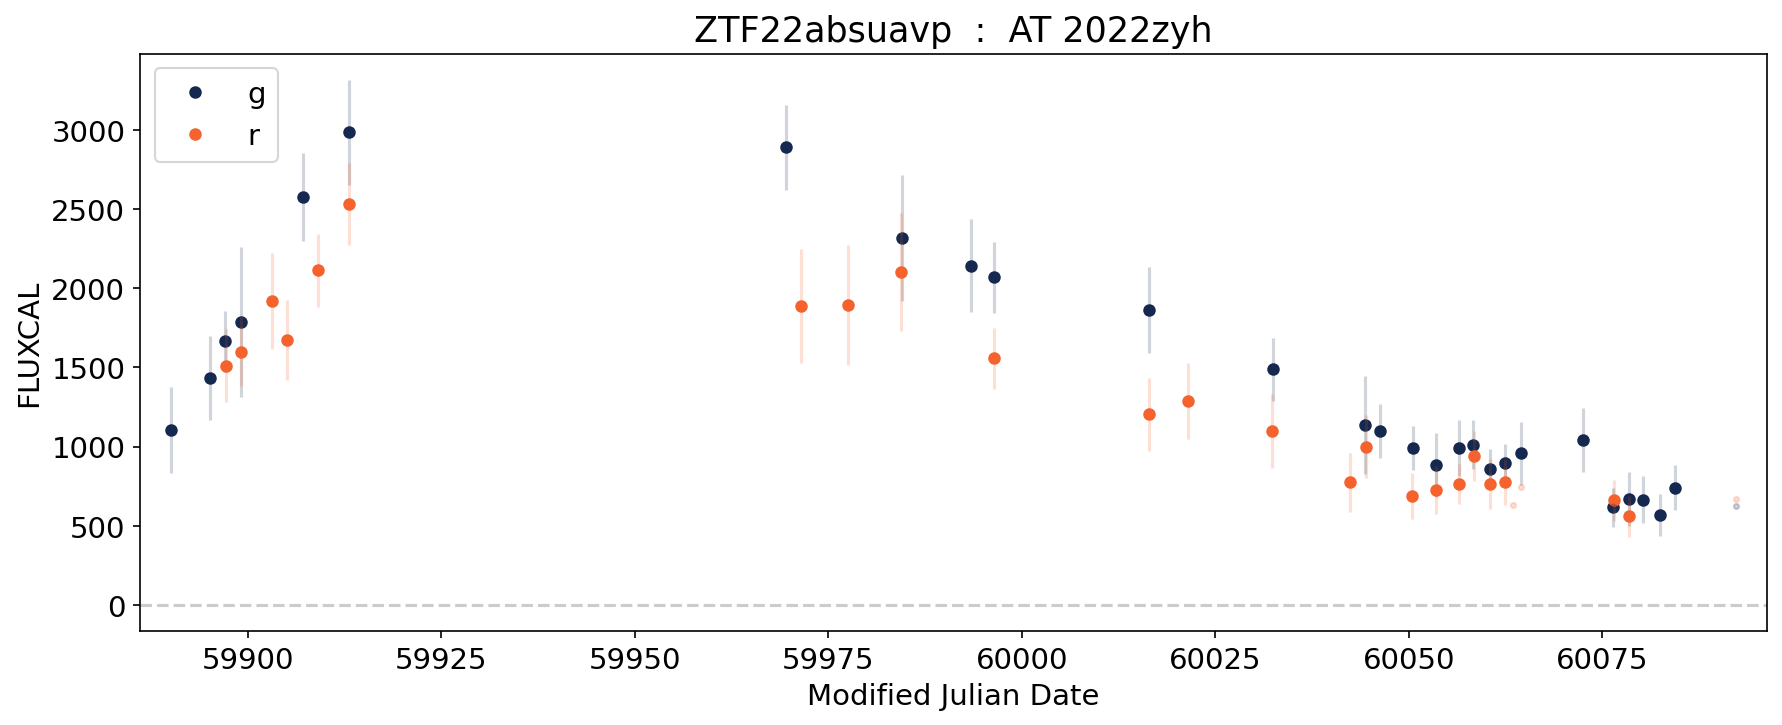

In [318]:
cand_idx = np.isin(features['objectId'], example_objs)
cand_idx &= features['counter'] == 0

# for i,cand in enumerate(features[cand_idx]):
for i,cand in enumerate([{'objectId':_} for _ in ['ZTF22absuavp']]):#example_objs]):
    print(cand['objectId'])

    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    full = full[full['i:sigmapsf'] < 0.3]
    
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    snad = request_lc_snad(ra, dec, 1.5)
    
    plt.figure(figsize=(14, 5))
    plot_lc(full, show_limits=False, show_zero=True, ms=10)
    plt.grid(None)
    
    # SNAD
    if snad is not None:
        for c,cn,fid in ((COLORS_ZTF[1], 'g', 1), (COLORS_ZTF[2], 'r', 2)):
            idx = nearests['objectId'] == cand['objectId']
            idx &= (np.isfinite(nearests['magnr_'+cn])) & (nearests['distnr_'+cn] < 1.5)
            if np.sum(idx):
                flux0 = 10**(11 - 0.4*np.mean(nearests['magnr_'+cn][idx]))
                flux0 = deredden(flux0, fid, ra, dec)
            else:
                flux0 = 0

            idx = snad['i:fid'] == fid
            plt.plot(snad['i:jd'][idx]-2400000.5, snad['FLUXCAL'][idx] - flux0, '.', ms=5, alpha=0.2, color=c)
            
    tns_info = get_tns_info(ra=ra, dec=dec) or 'no TNS info'
    plt.title(cand['objectId'] + '  :  ' + tns_info)
    plt.margins(0.02, 0.05)

#     plt.ylim(None, 1.2*np.max(full['FLUXCAL']))
    plt.ylabel('FLUXCAL')
    
    plt.legend(loc='upper left')
    
    plt.xlabel('Modified Julian Date')
    plt.ylabel('FLUXCAL')

    plt.savefig(f"/home/karpov/fink/tde/figures/fig_lc_{cand['objectId']}.pdf", bbox_inches='tight')
    plt.show()
    

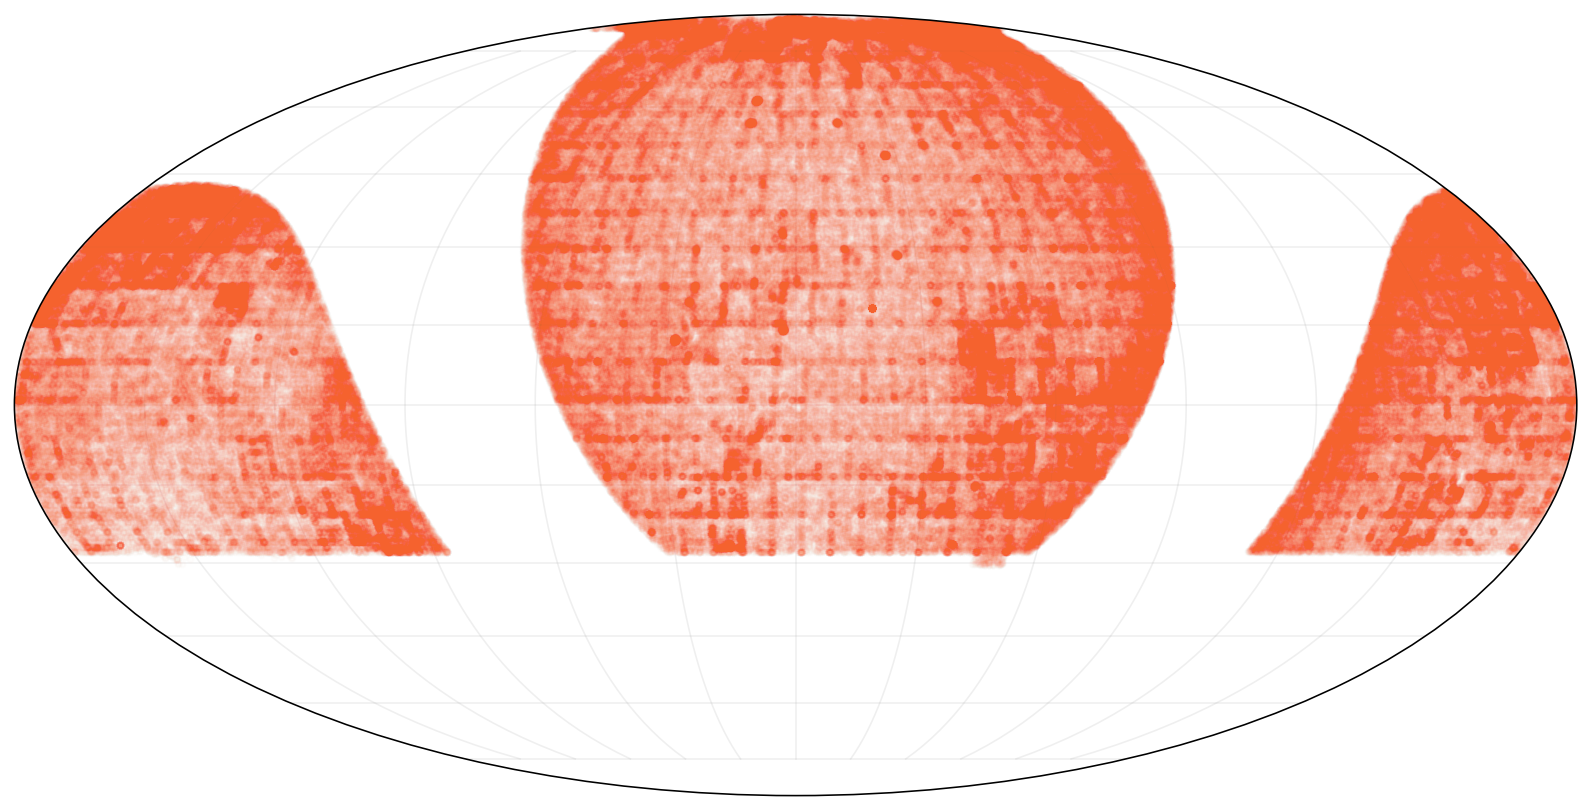

In [145]:
plt.figure()
ax = plt.subplot(111, projection="mollweide")
ax.grid(alpha=0.2)
ax.set_xticklabels([])
ax.set_yticklabels([])
    
ax.plot(np.deg2rad(data['i:ra']) - np.pi, np.deg2rad(data['i:dec']), '.', color=COLORS_ZTF[2], alpha=0.01)

Text(0.5, 0, 'Number of detections')

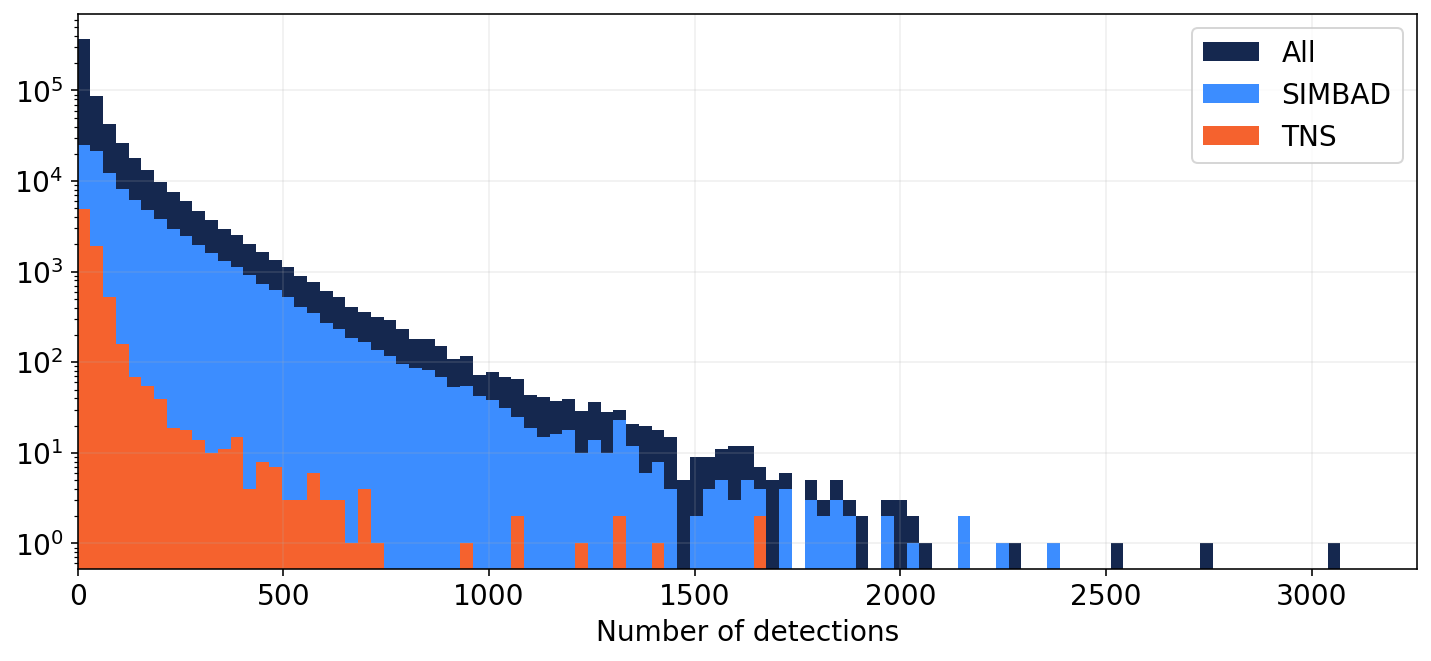

In [170]:
plt.figure(figsize=(12, 5))
vals = np.array([np.sum(np.isfinite(_)) for _ in data['FLUXCAL']])
plt.hist(vals, bins=100, range=[0, 3100], color=COLORS_ZTF[1], alpha=1, label='All')

idx = [np.sum(_ != 'Unknown') > 0 for _ in data['d:cdsxmatch']]
plt.hist(vals[idx], bins=100, range=[0, 3100], color=COLORS_ZTF[3], alpha=1, label='SIMBAD')

idx = data['tns'].astype(str) != 'nan'
plt.hist(vals[idx], bins=100, range=[0, 3100], color=COLORS_ZTF[2], alpha=1, label='TNS')

plt.legend()

plt.yscale('log')
plt.grid(alpha=0.2)
plt.xlim(0,)
plt.xlabel('Number of detections')

In [163]:
data['tns'][data['tns'].astype(str) != 'nan']


503       SN Ia
1845      SN Ia
1865      SN Ia
2298      SN Ia
2337      SN Ia
          ...  
603167    SN Ia
603184    SN Ia
603191    SN Ia
603197    SN Ia
603206    SN II
Name: tns, Length: 7799, dtype: object

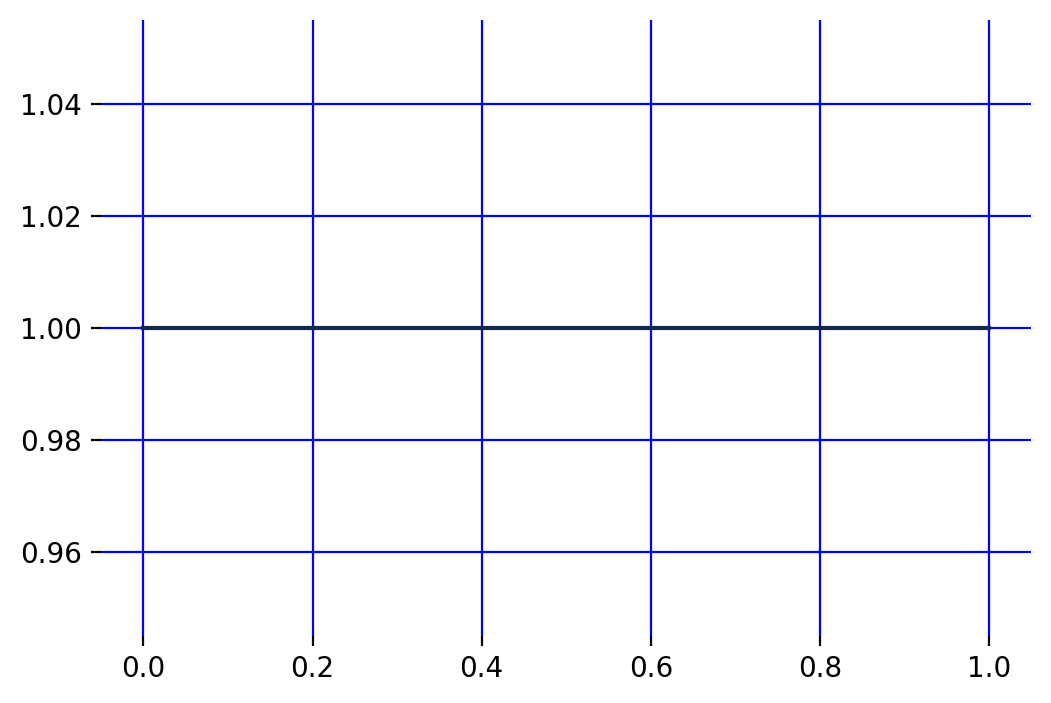

In [241]:
plt.figure(figsize=(6,4))
ax = plt.subplot(1,1,1)
ax.set_frame_on(False)
ax.set_facecolor(COLORS_ZTF[4])
ax.plot([0, 1], [1, 1], color=COLORS_ZTF[1])
# ax.xaxis.set_visible(False)  # Hide X-axis
# ax.yaxis.set_visible(False)  # Hide Y-axis
# ax.set_axis_off()
plt.grid(color='blue')


In [283]:
plt.rcdefaults()
plt.rcParams['font.size'] = 14
plt.rcParams['figure.dpi'] = 75

Text(0.5, 1.0, 'sigmoid')

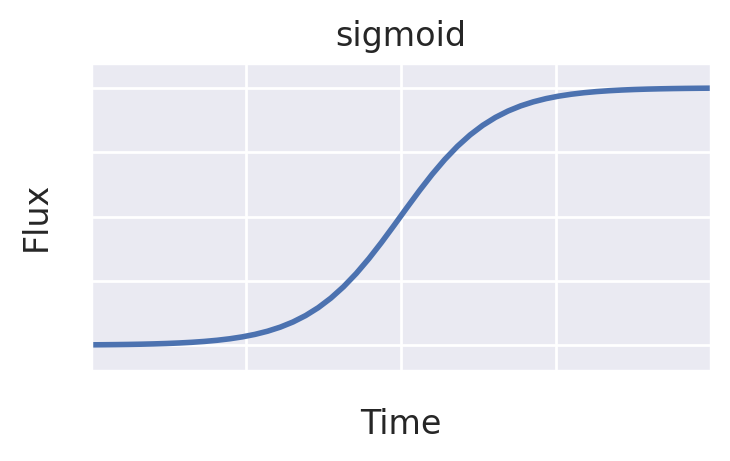

In [280]:
import seaborn as sns
sns.set_theme(style="darkgrid")

x = np.linspace(-10, 10)
y,name,ylabel = 0*x + 1, 'constant', 'Temperature'
# y,name,ylabel = 1 + 1/(1.0 + np.exp(x/1.5)), 'sigmoid', 'Temperature'
# y,name,ylabel = 1/(np.exp(-(x+5)/1) + np.exp((x+5)/4)), 'Bazin', 'Flux'
y,name,ylabel = 1/(1.0 + np.exp(-x/1.5)), 'sigmoid', 'Flux'

plt.figure(figsize=(4,2))
plt.plot(x, y, lw=2)
plt.gca().set_xticklabels([])
plt.gca().set_yticklabels([])
# plt.axis('off')
plt.margins(0, 0.1)

plt.xlabel('Time')
plt.ylabel(ylabel)
plt.title(name)


1 candidates
0 ZTF23abjvojy True 1 0


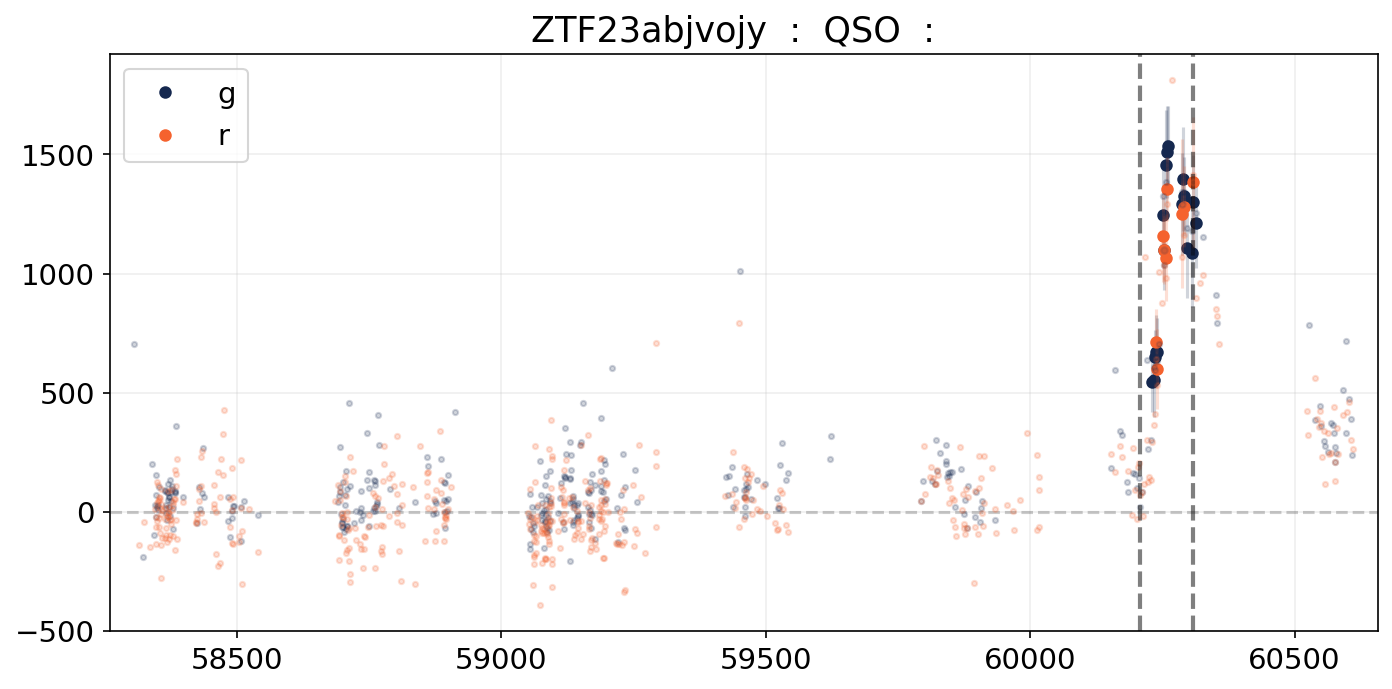

In [460]:
cand_idx = (tde_score == 1) | (tde_score_nodistnr == 1)
# cand_idx &= good_idx & ~tns_all_idx  # Good non-TNS candidates
# cand_idx &= good_idx & tns_all_idx # Good TNS candidates
cand_idx &= good_idx # Good candidates
# cand_idx &= good_idx & ~tns_all_idx # Good non-TNS candidates
cand_idx &= ~tde_idx # Exclude known TDEs
cand_idx &= ~sn_idx # Exclude known SNe
# cand_idx &= tde_idx # only known TDEs
# cand_idx &= features['num_prehist_negatives'] > 1

cand_idx = np.isin(features['objectId'], already_found)

cand_idx = features['objectId']=='ZTF23abjvojy'
# cand_idx &= features['distnr'] > 0.4
# cand_idx = np.isin(features['objectId'], ['ZTF18aanlzzf'])
# cand_idx = features['objectId'] == 'ZTF18aankgjw'
# cand_idx &= features['counter']-features['pcounter']==38
# cand_idx &= features['rise_time'] > 10
# cand_idx &= features['num_prehist_detections'] <= 1 # Exclude everything with history prior to 100 days
# cand_idx &= features['num_prehist_detections'] <= 1
# cand_idx &= features['num_prehist_negatives'] <= 1
cand_idx &= features['pcounter'] == 0
# cand_idx &= features['distnr'] > 1


# cand_found_idx = cand_idx & np.isin(features['objectId'], already_found)
# cand_idx &= ~np.isin(features['objectId'], already_found)


print(np.sum(cand_idx), 'candidates')

NN = 0
for i,cand in enumerate(features[cand_idx]):
#     if i < 500:
#         continue
    print(i, cand['objectId'], good_idx[cand_idx][i], tde_score[cand_idx][i], tde_score_nodistnr[cand_idx][i])
#     display(cand)
    full = get_lc(data[data['objectId'] == cand['objectId']].iloc[0])
    sub = full[(full['i:jd'] >= cand['jd_min']) & (full['i:jd'] <= cand['jd_max'])]
    sub = cleanup_limits(sub)
        
    ra,dec = np.mean(data[data['objectId']==cand['objectId']][['i:ra', 'i:dec']], axis=0)
    
    snad = request_lc_snad(ra, dec, 1.5)
    
    if NN == 0:
        plt.figure(figsize=(24,5))
    plt.subplot(1, 2, NN+1)
    plot_lc(full, show_limits=False, show_zero=True, ms=10)
    
    # SNAD
    if snad is not None:
        for c,cn,fid in ((COLORS_ZTF[1], 'g', 1), (COLORS_ZTF[2], 'r', 2)):
            idx = nearests['objectId'] == cand['objectId']
            idx &= (np.isfinite(nearests['magnr_'+cn])) & (nearests['distnr_'+cn] < 1.5)
            if np.sum(idx):
                flux0 = 10**(11 - 0.4*np.mean(nearests['magnr_'+cn][idx]))
                flux0 = deredden(flux0, fid, ra, dec)
            else:
                flux0 = 0

            idx = snad['i:fid'] == fid
            plt.plot(snad['i:jd'][idx]-2400000.5, snad['FLUXCAL'][idx] - flux0, '.', ms=5, alpha=0.2, color=c)
            
    plt.axvline(cand['jd_min']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    plt.axvline(cand['jd_max']-2400000.5, ls='--', color='black', alpha=0.5, lw=2)
    
#     plt.axvspan(cand['jd_min']-2400000.5-100, cand['jd_min']-2400000.5, color='gray', hatch='//', fc='white', lw=0.5, alpha=0.5)
    plt.title(cand['objectId'] + '  :  ' + cand['type'] + '  :  ' + get_tns_info(ra=ra, dec=dec))
    plt.margins(0.02, 0.05)

    plt.legend(loc='upper left')
    
    if NN == 1:
        plt.show()
        NN = 0
    else:
        NN += 1

In [320]:
np.sum(features['pcounter']==0)

np.int64(80997)

In [321]:
np.sum(good_idx)

np.int64(12600)

In [325]:
print(len(features))

good_idx = features['pcounter'] == 0 # Only last sets of features for every peak
print(np.sum(good_idx))

good_idx &= features['r_chisq'] < 10
print(np.sum(good_idx))

good_idx &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window
print(np.sum(good_idx))

# good_idx &= features['num_prehist_detections'] <= 1 # No more than 1 detection prior to the window
good_idx &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window
print(np.sum(good_idx))

good_idx &= features['e_reference_time'] < 100
print(np.sum(good_idx))

good_idx &= features['norm_rel_reference_time'] < 0
good_idx &= features['norm_rel_reference_time'] > -10
print(np.sum(good_idx))

# good_idx &= features['snr_amplitude'] > 1.5
good_idx &= features['snr_rise_time'] > 1.5
good_idx &= features['snr_temperature'] > 1.5
print(np.sum(good_idx))

print(np.sum(good_idx))


349104
80997
80997
45145
40684
32016
19094
12600
12600


In [329]:
np.sum(good_idx & ~tns_all_idx)

np.int64(3737)

In [347]:
features['Ebv'] = np.nan

In [468]:
from dustmaps.sfd import SFDQuery
from dustmaps.csfd import CSFDQuery

sfd = SFDQuery()

v1,v2, v3, v4 = [],[],[],[]

for cand in tqdm(features[good_idx & tns_all_idx]):
    sub = data[data['objectId'] == cand['objectId']].iloc[0]
    
    v3.append(sub['i:ra'])
    v4.append(sub['i:dec'])
    
    Ebv = sfd(SkyCoord(sub['i:ra'], sub['i:dec'], unit='deg'))
    
    v1.append(cand['temperature'])
    v2.append(Ebv)
    
#     print(cand['objectId'], cand['tns_name'], cand['temperature'], Ebv)
    pass

  0%|          | 0/8863 [00:00<?, ?it/s]

KeyboardInterrupt: 

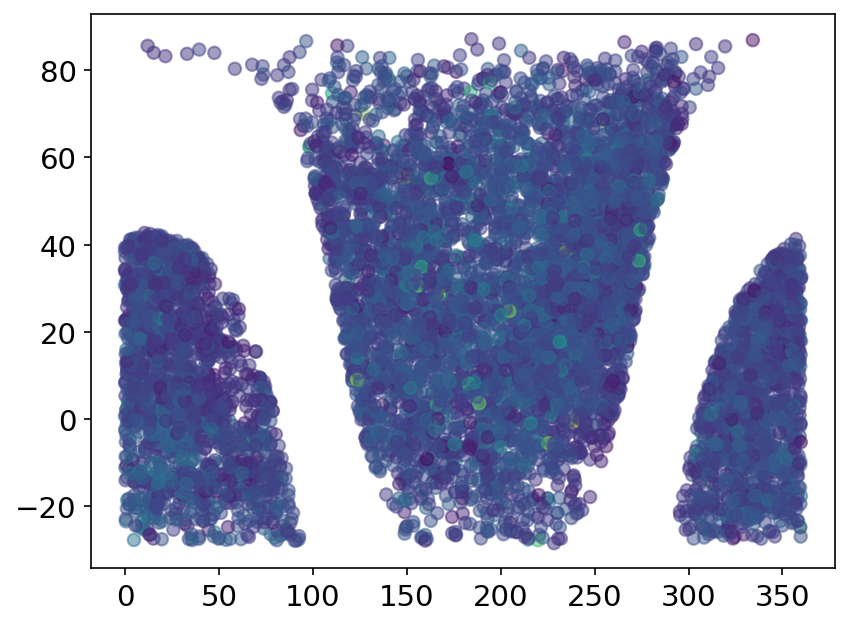

In [404]:
plt.scatter(v3, v4, marker='o', c=v1, alpha=0.5)

Text(0.5, 1.0, 'Original')

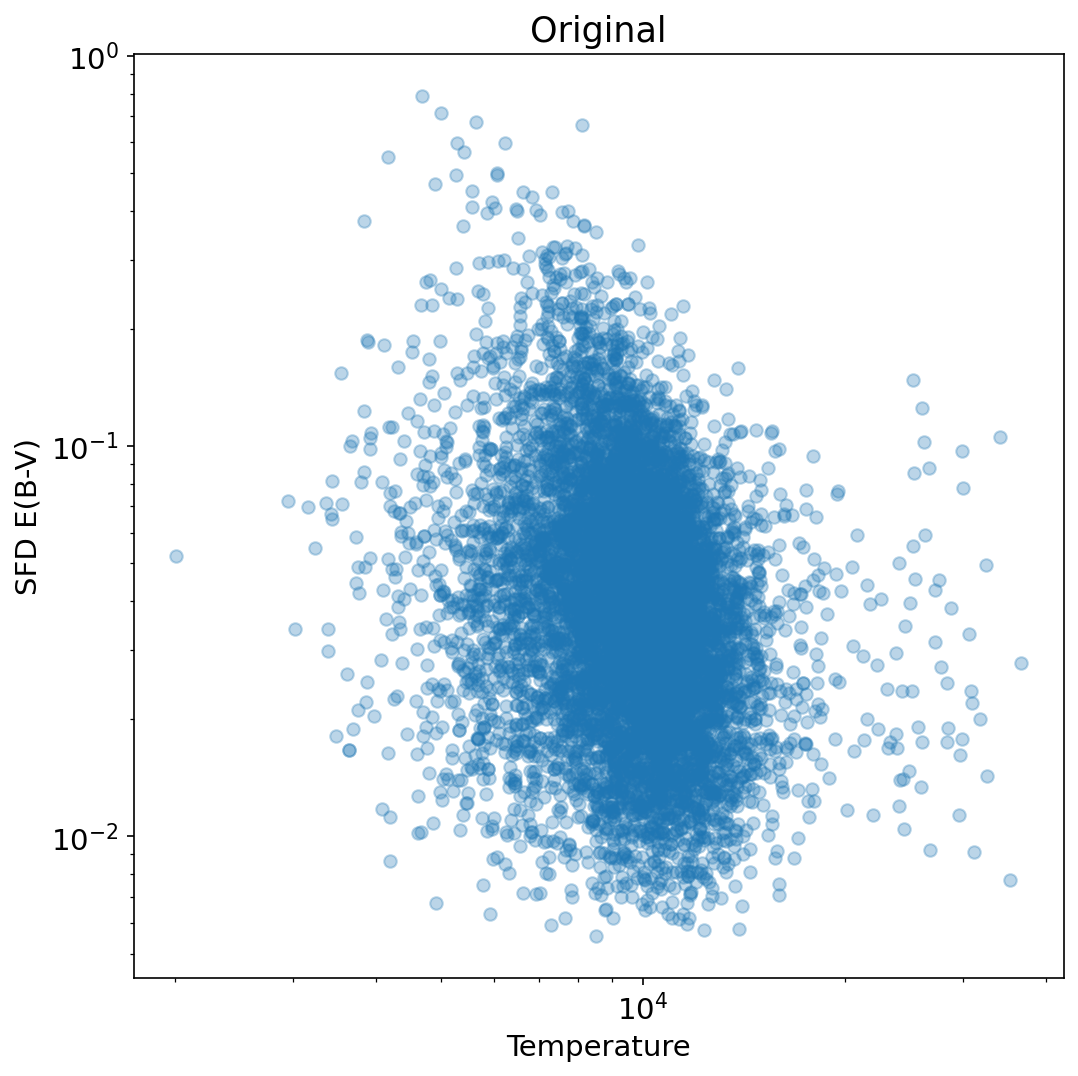

In [458]:
plt.figure(figsize=(8,8))
plt.plot(v1, v2, 'o', alpha=0.3)
plt.xscale('log')
plt.yscale('log')
# plt.xlim(None, 1e4)
plt.xlabel('Temperature')
plt.ylabel('SFD E(B-V)')
plt.title('Original')

In [456]:
len(v1)

8863

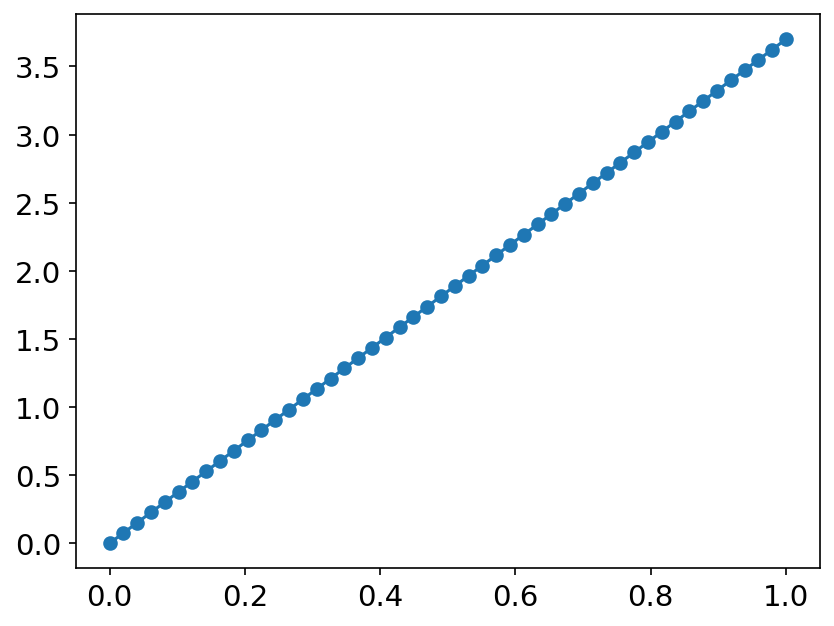

In [463]:
from dust_extinction.parameter_averages import G23,CCM89

# ext = G23(Rv=3.1)
ext = CCM89(Rv=3.1)

# x = np.linspace(0, 1)
# plt.plot(x, [-2.5*np.log10(ext.extinguish(band_wave_aa['g']*u.AA, Ebv=_)) for _ in x], 'o-')

In [467]:
ext = G23(Rv=3.1)
# ext = CCM89(Rv=3.1)

for _ in ['g', 'r', 'i']:
    print(_, -2.5*np.log10(ext.extinguish(band_wave_aa[_]*u.AA, Ebv=1)))

g 3.7002659677911547
r 2.695100938086194
i 2.0250837322749686


In [389]:
np.min(v1)

np.float64(8278.290896419348)

In [ ]:
sfd()